# **Import Libraries**

In [1]:
import pandas as pd # to load the dataset

# analysis module
import matplotlib.pyplot as plt # to analysis the data
import seaborn as sns # to analysis the data

# to split the dataset, load the models, traning and testing

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import accuracy_score, classification_report, f1_score, recall_score, precision_score
from sklearn.decomposition import PCA 
from sklearn.preprocessing import StandardScaler, LabelEncoder, label_binarize
import numpy as np
from sklearn.feature_selection import VarianceThreshold
from sklearn.ensemble import RandomForestClassifier 
from xgboost import XGBClassifier
from sklearn.ensemble import ExtraTreesClassifier, AdaBoostClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score, roc_curve, auc, confusion_matrix, ConfusionMatrixDisplay


from scipy.fftpack import fft
from scipy.signal import find_peaks, welch
import pywt
#from statsmodels.tsa.ar_model import AutoReg

# to ignore unnecessary warnings
import warnings 
warnings.filterwarnings('ignore')

# **Load datasets**

In [2]:
flicker_df = pd.read_csv("/kaggle/input/seed-power-quality-disturbance-dataset/XPQRS/Flicker.csv")
flicker_with_sag_df = pd.read_csv("/kaggle/input/seed-power-quality-disturbance-dataset/XPQRS/Flicker_with_Sag.csv")
flicker_with_swell_df = pd.read_csv("/kaggle/input/seed-power-quality-disturbance-dataset/XPQRS/Flicker_with_Swell.csv")
harmonics_df = pd.read_csv("/kaggle/input/seed-power-quality-disturbance-dataset/XPQRS/Harmonics.csv")
harmonics_with_sag_df = pd.read_csv("/kaggle/input/seed-power-quality-disturbance-dataset/XPQRS/Harmonics_with_Sag.csv")
harmonics_with_swell_df = pd.read_csv("/kaggle/input/seed-power-quality-disturbance-dataset/XPQRS/Harmonics_with_Swell.csv")
interruption_df = pd.read_csv("/kaggle/input/seed-power-quality-disturbance-dataset/XPQRS/Interruption.csv")
notch_df = pd.read_csv("/kaggle/input/seed-power-quality-disturbance-dataset/XPQRS/Notch.csv")
oscillatory_transient_df = pd.read_csv("/kaggle/input/seed-power-quality-disturbance-dataset/XPQRS/Oscillatory_Transient.csv")
pure_sinusoidal_df = pd.read_csv("/kaggle/input/seed-power-quality-disturbance-dataset/XPQRS/Pure_Sinusoidal.csv")
sag_df = pd.read_csv("/kaggle/input/seed-power-quality-disturbance-dataset/XPQRS/Sag.csv")
sag_with_harmonics_df = pd.read_csv("/kaggle/input/seed-power-quality-disturbance-dataset/XPQRS/Sag_with_Harmonics.csv")
sag_with_oscillatory_transient_df = pd.read_csv("/kaggle/input/seed-power-quality-disturbance-dataset/XPQRS/Sag_with_Oscillatory_Transient.csv")
swell_df = pd.read_csv("/kaggle/input/seed-power-quality-disturbance-dataset/XPQRS/Swell.csv")
swell_with_harmonics_df = pd.read_csv("/kaggle/input/seed-power-quality-disturbance-dataset/XPQRS/Swell_with_Harmonics.csv")
swell_with_oscillatory_transient_df = pd.read_csv("/kaggle/input/seed-power-quality-disturbance-dataset/XPQRS/Swell_with_Oscillatory_Transient.csv")
transient_df = pd.read_csv("/kaggle/input/seed-power-quality-disturbance-dataset/XPQRS/Transient.csv")

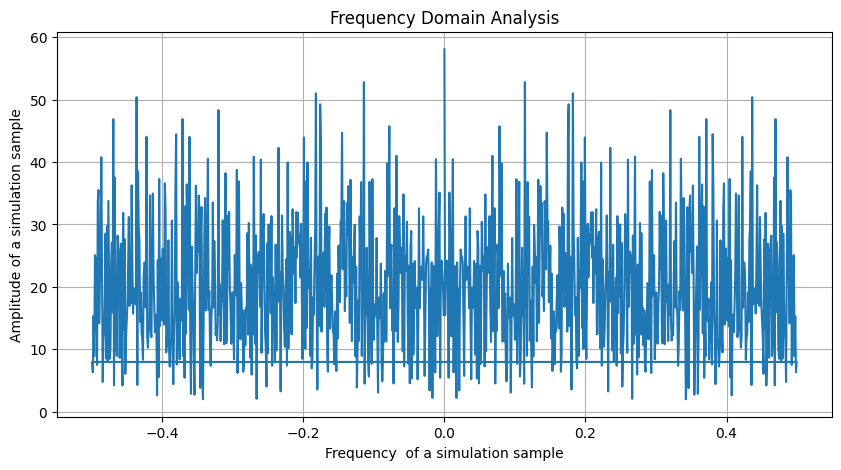

In [5]:
import numpy as np

# Select a single column for Fourier Transform
column_to_analyze = harmonics_df.columns[0]
data = harmonics_df[column_to_analyze]

# Fourier Transform
frequency_spectrum = np.fft.fft(data)
frequencies = np.fft.fftfreq(len(data))

# Plotting the Frequency Spectrum
plt.figure(figsize=(10, 5))
plt.plot(frequencies, np.abs(frequency_spectrum))
plt.xlabel("Frequency  of a simulation sample")
plt.ylabel("Amplitude of a simulation sample")
plt.title(f"Frequency Domain Analysis")
plt.grid(True)
plt.show()

# **generating classes**

In [6]:
flicker_df['class'] = 'Flicker'
flicker_with_sag_df['class'] = 'Flicker with Sag'
flicker_with_swell_df['class'] = 'Flicker with Swell'
harmonics_df['class'] = 'Harmonics' 
harmonics_with_sag_df['class'] = 'Harmonics with Sag'
harmonics_with_swell_df['class'] = 'Harmonics with Swell'
interruption_df['class'] = 'Interruption'
notch_df['class'] = 'Notch'
oscillatory_transient_df['class'] = 'Oscillatory Transient'
pure_sinusoidal_df['class'] = 'Pure Sinusoidal'
sag_df['class'] = 'Sag'
sag_with_harmonics_df['class'] = 'Sag with Harmonics'
sag_with_oscillatory_transient_df['class'] = 'Sag with Oscillatory'
swell_df['class'] = 'Swell'
swell_with_harmonics_df['class'] = 'Swell with Harmonics'
swell_with_oscillatory_transient_df['class'] = 'Swell with Oscillatory Transient'
transient_df['class'] = 'Transient'

# **Rename the columns**

In [7]:
# rename columns based on a predefined pattern or logic
def rename_columns(df):
    # Example: Rename columns as 'Column_1', 'Column_2', etc.
    new_column_names = [f"Column_{i+1}" for i in range(len(df.columns))]
    df.columns = new_column_names
    return df

In [8]:
flicker_df = rename_columns(flicker_df)
flicker_with_sag_df = rename_columns(flicker_with_sag_df)
flicker_with_swell_df = rename_columns(flicker_with_swell_df)
harmonics_df = rename_columns(harmonics_df)
harmonics_with_sag_df = rename_columns(harmonics_with_sag_df)
harmonics_with_swell_df = rename_columns(harmonics_with_swell_df)
interruption_df = rename_columns(interruption_df)
notch_df = rename_columns(notch_df)
oscillatory_transient_df = rename_columns(oscillatory_transient_df)
pure_sinusoidal_df = rename_columns(pure_sinusoidal_df)
sag_df = rename_columns(sag_df)
sag_with_harmonics_df = rename_columns(sag_with_harmonics_df)
sag_with_oscillatory_transient_df = rename_columns(sag_with_oscillatory_transient_df)
swell_df = rename_columns(swell_df)
swell_with_harmonics_df = rename_columns(swell_with_harmonics_df)
swell_with_oscillatory_transient_df = rename_columns(swell_with_oscillatory_transient_df)
transient_df = rename_columns(transient_df)

# **Combine all the data into a single one**

In [9]:
combined_df = pd.concat([flicker_df, flicker_with_sag_df, flicker_with_swell_df, harmonics_df, harmonics_with_sag_df, harmonics_with_swell_df, interruption_df, notch_df, oscillatory_transient_df, pure_sinusoidal_df, sag_df, sag_with_harmonics_df,sag_with_oscillatory_transient_df, swell_df,swell_with_harmonics_df, swell_with_oscillatory_transient_df, transient_df], axis=0)
combined_df.shape

(16983, 101)

In [10]:
#final format of the dataset
resample_df = combined_df.sample(frac=1,random_state=42).reset_index(drop=True)
resample_df.head()         
#resample_df.to_csv("PQD.csv")

,Column_1,Column_2,Column_3,Column_4,Column_5,Column_6,Column_7,Column_8,Column_9,Column_10,...,Column_92,Column_93,Column_94,Column_95,Column_96,Column_97,Column_98,Column_99,Column_100,Column_101
0,0.095917,0.153063,0.212028,0.273147,0.336276,0.400790,0.465618,0.529341,0.590324,0.646883,...,-0.603413,-0.507081,-0.414284,-0.326173,-0.243196,-0.165131,-0.091179,-0.020116,0.049515,Harmonics with Swell
1,0.967636,0.983320,0.995166,1.003109,1.007103,1.007117,1.003136,0.995158,0.983202,0.967300,...,0.580890,0.617666,0.651846,0.683304,0.711927,0.737612,0.760270,0.936748,0.956769,Flicker with Sag
2,-0.937272,-0.957311,-0.973572,-0.985991,-0.994519,-0.999122,-0.999781,-0.996495,-0.989277,-0.978154,...,-0.899237,-0.987655,-1.073017,-1.153995,-1.229331,-1.297921,-1.358886,-1.411624,-1.455838,Swell with Harmonics
3,0.000000,0.062791,0.125333,0.187381,0.248690,0.309017,0.368125,0.425779,0.481754,0.535827,...,-0.046466,-0.041777,-0.036923,-0.031923,-0.026798,-0.021566,-0.016250,-0.010869,-0.005445,Interruption
4,-0.093190,-0.149109,-0.175381,-0.180893,-0.177200,-0.176275,-0.188286,-0.219817,-0.272843,-0.344641,...,0.960631,0.927557,0.851659,0.736532,0.591511,0.430117,0.267803,0.119401,-0.003265,Harmonics


# **Data Analysis** 

In [11]:
print(f"Number of null values: {resample_df.isna().sum().sum()}")
print(f"Data Types: {resample_df.dtypes}\n\n")
print(f"Number of classes: {resample_df['Column_101'].value_counts()}")

Number of null values: 0
Data Types: Column_1      float64
Column_2      float64
Column_3      float64
Column_4      float64
Column_5      float64
               ...   
Column_97     float64
Column_98     float64
Column_99     float64
Column_100    float64
Column_101     object
Length: 101, dtype: object


Number of classes: Column_101
Harmonics with Swell                999
Harmonics with Sag                  999
Sag with Harmonics                  999
Oscillatory Transient               999
Transient                           999
Pure Sinusoidal                     999
Flicker                             999
Sag with Oscillatory                999
Notch                               999
Flicker with Sag                    999
Swell with Oscillatory Transient    999
Sag                                 999
Flicker with Swell                  999
Harmonics                           999
Interruption                        999
Swell with Harmonics                999
Swell                 

In [12]:
resample_df.isna().sum(), resample_df.columns

(Column_1      0
 Column_2      0
 Column_3      0
 Column_4      0
 Column_5      0
              ..
 Column_97     0
 Column_98     0
 Column_99     0
 Column_100    0
 Column_101    0
 Length: 101, dtype: int64,
 Index(['Column_1', 'Column_2', 'Column_3', 'Column_4', 'Column_5', 'Column_6',
        'Column_7', 'Column_8', 'Column_9', 'Column_10',
        ...
        'Column_92', 'Column_93', 'Column_94', 'Column_95', 'Column_96',
        'Column_97', 'Column_98', 'Column_99', 'Column_100', 'Column_101'],
       dtype='object', length=101))

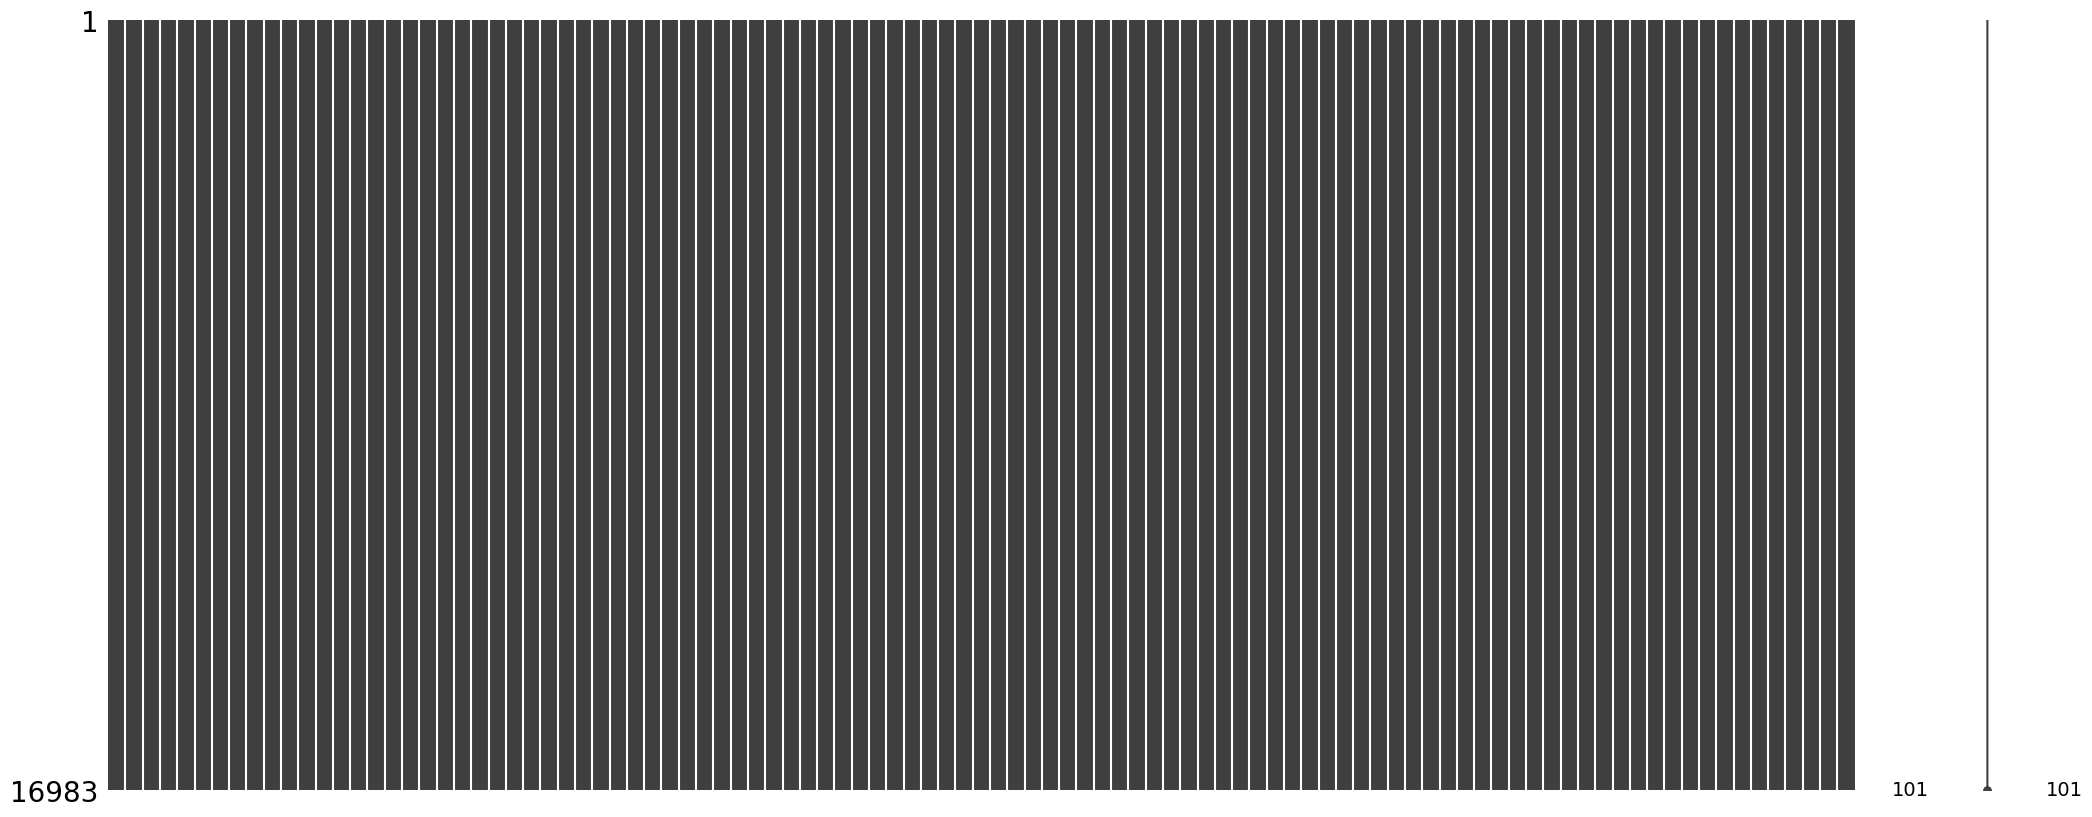

In [13]:
import missingno as msno
msno.matrix(resample_df)
plt.show()

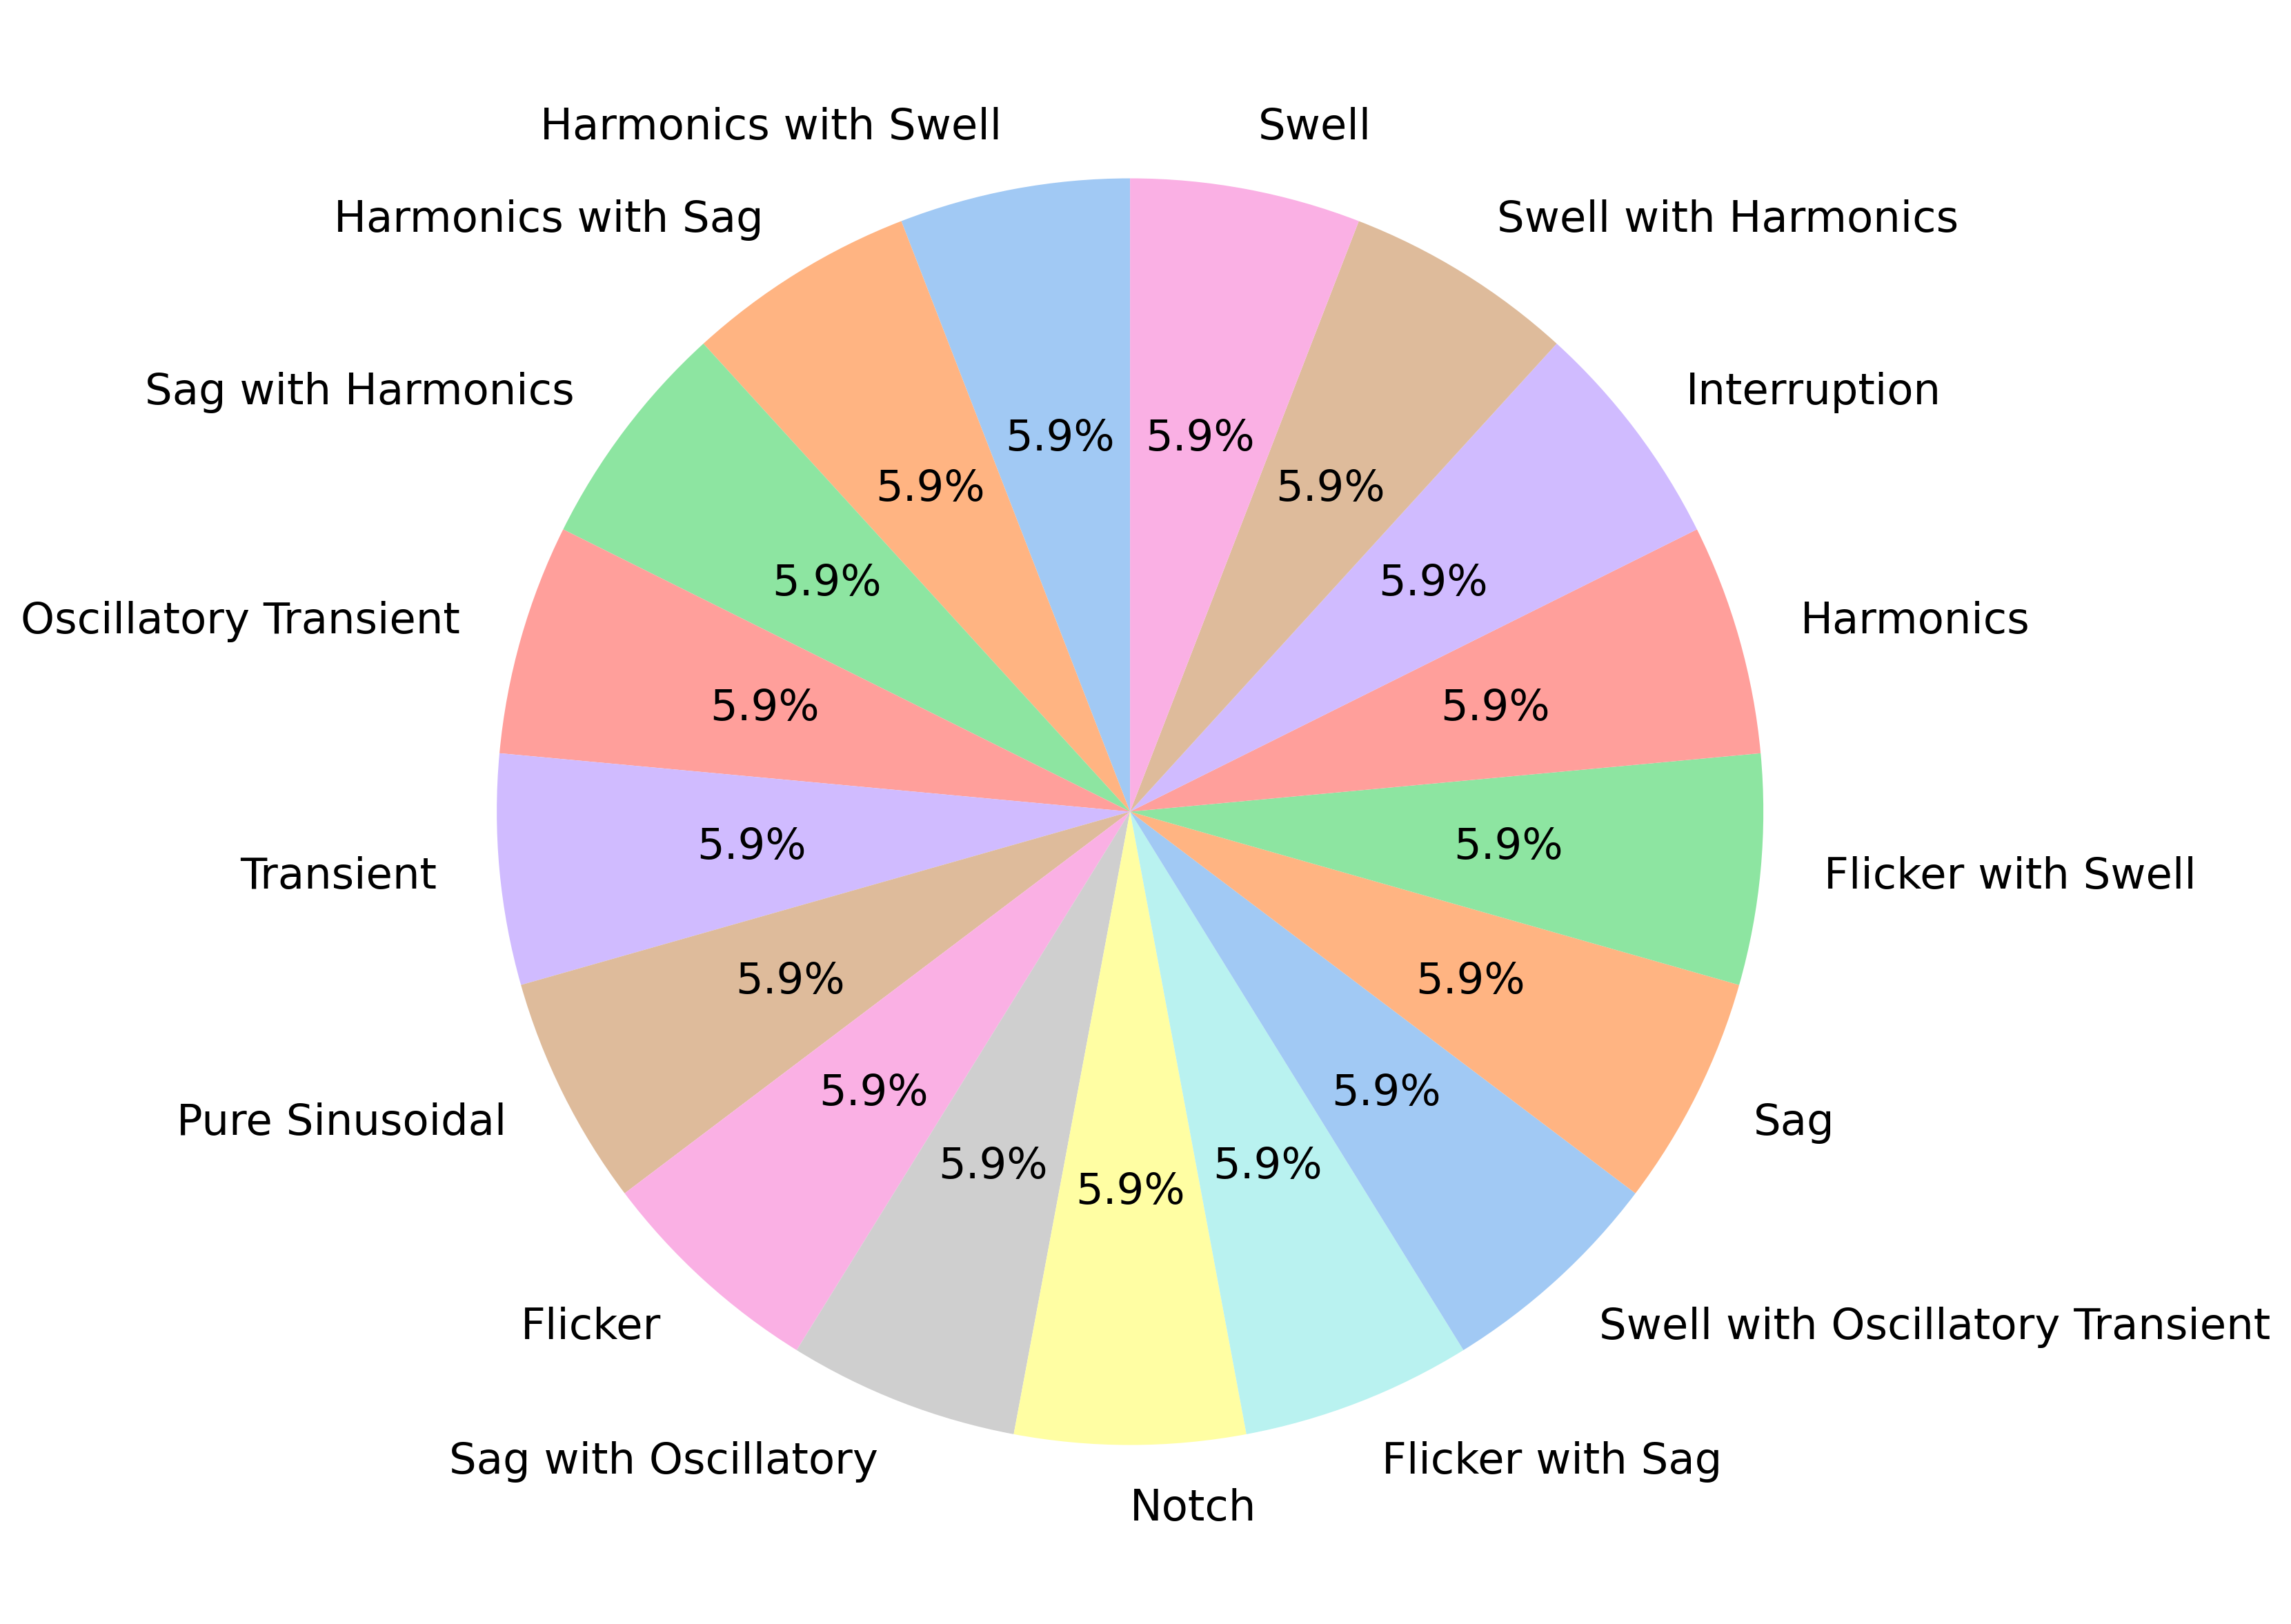

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

# Aggregating counts for each category
category_counts = resample_df['Column_101'].value_counts()

# Pie chart visualization
plt.figure(figsize=(10, 8), dpi=300)  # High resolution and size

# Creating the pie chart
plt.pie(category_counts, labels=category_counts.index, 
        autopct='%1.1f%%', startangle=90, 
        colors=sns.color_palette("pastel", len(category_counts)), 
        textprops={'fontsize': 15, 'fontname': 'Arial'})

# Adding a title
#plt.title('Distribution of PQ Disturbances', fontdict={'fontname': 'Arial', 'fontsize': 20})

plt.tight_layout()
plt.savefig('PQD_pie.png', dpi=300, bbox_inches='tight', format='png')
plt.show()

In [15]:
pqd_data_cleaned = resample_df
# Select numerical features
numerical_features = pqd_data_cleaned.iloc[:, :-1]

In [16]:
numerical_features.head()

,Column_1,Column_2,Column_3,Column_4,Column_5,Column_6,Column_7,Column_8,Column_9,Column_10,...,Column_91,Column_92,Column_93,Column_94,Column_95,Column_96,Column_97,Column_98,Column_99,Column_100
0,0.095917,0.153063,0.212028,0.273147,0.336276,0.400790,0.465618,0.529341,0.590324,0.646883,...,-0.701472,-0.603413,-0.507081,-0.414284,-0.326173,-0.243196,-0.165131,-0.091179,-0.020116,0.049515
1,0.967636,0.983320,0.995166,1.003109,1.007103,1.007117,1.003136,0.995158,0.983202,0.967300,...,0.541655,0.580890,0.617666,0.651846,0.683304,0.711927,0.737612,0.760270,0.936748,0.956769
2,-0.937272,-0.957311,-0.973572,-0.985991,-0.994519,-0.999122,-0.999781,-0.996495,-0.989277,-0.978154,...,-0.809065,-0.899237,-0.987655,-1.073017,-1.153995,-1.229331,-1.297921,-1.358886,-1.411624,-1.455838
3,0.000000,0.062791,0.125333,0.187381,0.248690,0.309017,0.368125,0.425779,0.481754,0.535827,...,-0.050972,-0.046466,-0.041777,-0.036923,-0.031923,-0.026798,-0.021566,-0.016250,-0.010869,-0.005445
4,-0.093190,-0.149109,-0.175381,-0.180893,-0.177200,-0.176275,-0.188286,-0.219817,-0.272843,-0.344641,...,0.953603,0.960631,0.927557,0.851659,0.736532,0.591511,0.430117,0.267803,0.119401,-0.003265


# **Feature Engineering**

## **Statistical Features**

In [17]:
# Generate statistical features for each row
scaler = StandardScaler()
scaled_features = scaler.fit_transform(numerical_features)
scaled_df = pd.DataFrame(scaled_features, columns=numerical_features.columns)

# Statistical Features Extraction
stat_features = pd.DataFrame()
stat_features['mean'] = numerical_features.mean(axis=1)
stat_features['std_dev'] = numerical_features.std(axis=1)
stat_features['min'] = numerical_features.min(axis=1)
stat_features['max'] = numerical_features.max(axis=1)
stat_features['skewness'] = numerical_features.skew(axis=1)
stat_features['kurtosis'] = numerical_features.kurt(axis=1)
stat_features['median'] = numerical_features.median(axis=1)
stat_features['iqr'] = numerical_features.quantile(0.75, axis=1) - numerical_features.quantile(0.25, axis=1)
stat_features['range'] = stat_features['max'] - stat_features['min']
stat_features['energy'] = (numerical_features**2).sum(axis=1)
stat_features['rms'] = np.sqrt((numerical_features**2).mean(axis=1))
stat_features['variance'] = numerical_features.var(axis=1)
stat_features['entropy'] = -(numerical_features * np.log1p(numerical_features)).sum(axis=1)

# Frequency-Domain Features (Fourier Transform)
fft_vals = np.abs(fft(numerical_features, axis=1))
stat_features['fft_mean'] = fft_vals.mean(axis=1)
stat_features['fft_std_dev'] = fft_vals.std(axis=1)
stat_features['fft_max'] = fft_vals.max(axis=1)
stat_features['fft_energy'] = (fft_vals**2).sum(axis=1)

# Wavelet Transform Features
def extract_wavelet_features(data, wavelet='db4'):
    coeffs = pywt.wavedec(data, wavelet, level=5)
    return [np.mean(np.abs(c)) for c in coeffs]

wavelet_features = numerical_features.apply(extract_wavelet_features, axis=1, result_type="expand")
wavelet_features.columns = [f'wavelet_coef_{i}' for i in range(wavelet_features.shape[1])]
stat_features = pd.concat([stat_features, wavelet_features], axis=1)

# Signal Shape Features
stat_features['crest_factor'] = stat_features['max'] / stat_features['rms']
stat_features['impulse_factor'] = stat_features['max'] / stat_features['mean']
stat_features['shape_factor'] = stat_features['rms'] / stat_features['mean']

In [18]:
stat_features.head()

,mean,std_dev,min,max,skewness,kurtosis,median,iqr,range,energy,...,fft_energy,wavelet_coef_0,wavelet_coef_1,wavelet_coef_2,wavelet_coef_3,wavelet_coef_4,wavelet_coef_5,crest_factor,impulse_factor,shape_factor
0,-7.034592e-02,0.798863,-1.253849,1.009019,-0.114411,-1.542148,-1.963916e-03,1.747679,2.262868,63.674862,...,6367.486212,2.170072,0.637564,0.324934,0.089455,0.017509,0.001549,1.264490,-1.434368e+01,-1.134345e+01
1,2.565453e-02,0.662251,-0.889270,1.007117,0.068435,-1.468954,3.310847e-04,1.270120,1.896388,43.484932,...,4348.493190,4.949774,0.390277,0.045844,0.025208,0.012235,0.004160,1.527252,3.925691e+01,2.570428e+01
2,-3.399867e-03,0.824652,-1.455838,1.394092,-0.020874,-1.419480,-6.076184e-03,1.644720,2.849929,67.326142,...,6732.614193,5.444369,0.704602,0.158398,0.058992,0.021950,0.004002,1.699024,-4.100430e+02,-2.413403e+02
3,2.344080e-01,0.406080,-0.086719,1.000000,0.979843,-0.820780,5.310002e-18,0.660521,1.086719,21.819932,...,2181.993154,1.041557,0.399090,0.111082,0.065394,0.018165,0.009776,2.140786,4.266065e+00,1.992756e+00
4,2.354280e-16,0.724023,-1.090403,1.090403,0.000000,-1.526276,8.500145e-16,1.492574,2.180805,51.896656,...,5189.665642,1.766336,0.526244,0.151525,0.255113,0.034124,0.001875,1.513621,4.631576e+15,3.059931e+15


In [19]:
# Apply PCA for Dimensionality Reduction
pca = PCA(n_components=10)
pca_features = pca.fit_transform(scaled_features)
pca_df = pd.DataFrame(pca_features, columns=[f'PC{i+1}' for i in range(10)])

# Combine all features
combined_features = pd.concat([scaled_df, stat_features, pca_df], axis=1)

# Add target variable back
final_dataset = pd.concat([combined_features,pqd_data_cleaned['Column_101']], axis=1)

In [20]:
final_dataset.head()

,Column_1,Column_2,Column_3,Column_4,Column_5,Column_6,Column_7,Column_8,Column_9,Column_10,...,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,Column_101
0,0.146057,0.215250,0.286439,0.360742,0.435304,0.512266,0.588314,0.660621,0.726708,0.785452,...,-0.685208,1.161498,0.206257,0.267560,0.130438,-0.561068,-0.495741,-0.681572,-0.091565,Harmonics with Swell
1,1.554292,1.556054,1.548562,1.530713,1.501614,1.467512,1.426866,1.379051,1.325145,1.267261,...,-9.206710,-0.212075,0.637447,0.351170,0.076330,0.021161,-0.012616,0.079467,0.016935,Flicker with Sag
2,-1.523028,-1.577922,-1.624305,-1.657381,-1.680054,-1.693244,-1.697778,-1.692674,-1.679359,-1.658103,...,11.199377,-0.179708,1.311910,-1.272918,0.711445,-0.502576,0.431605,-0.214572,0.208492,Swell with Harmonics
3,-0.008894,0.069467,0.146719,0.223279,0.296082,0.367681,0.436219,0.500898,0.561332,0.618458,...,-0.902456,-3.656427,0.372712,-0.864743,-0.974050,-0.251100,0.366217,-0.339574,-0.295338,Interruption
4,-0.159439,-0.272735,-0.337920,-0.366983,-0.380888,-0.396879,-0.431808,-0.494804,-0.588079,-0.705494,...,-1.225086,0.203334,-0.377274,-0.116805,-0.680789,0.309959,-0.144247,-1.108064,-0.655719,Harmonics


# **Label Encoding**

In [21]:
from sklearn.preprocessing import LabelEncoder
lbl = LabelEncoder()

final_dataset['Column_101'] = lbl.fit_transform(final_dataset['Column_101'])

In [22]:
lbl.classes_

array(['Flicker', 'Flicker with Sag', 'Flicker with Swell', 'Harmonics',
       'Harmonics with Sag', 'Harmonics with Swell', 'Interruption',
       'Notch', 'Oscillatory Transient', 'Pure Sinusoidal', 'Sag',
       'Sag with Harmonics', 'Sag with Oscillatory', 'Swell',
       'Swell with Harmonics', 'Swell with Oscillatory Transient',
       'Transient'], dtype=object)

In [23]:
for i, class_name in enumerate(lbl.classes_):
    print(f"Encoded value {i} → Class label: {class_name}")

Encoded value 0 → Class label: Flicker
Encoded value 1 → Class label: Flicker with Sag
Encoded value 2 → Class label: Flicker with Swell
Encoded value 3 → Class label: Harmonics
Encoded value 4 → Class label: Harmonics with Sag
Encoded value 5 → Class label: Harmonics with Swell
Encoded value 6 → Class label: Interruption
Encoded value 7 → Class label: Notch
Encoded value 8 → Class label: Oscillatory Transient
Encoded value 9 → Class label: Pure Sinusoidal
Encoded value 10 → Class label: Sag
Encoded value 11 → Class label: Sag with Harmonics
Encoded value 12 → Class label: Sag with Oscillatory
Encoded value 13 → Class label: Swell
Encoded value 14 → Class label: Swell with Harmonics
Encoded value 15 → Class label: Swell with Oscillatory Transient
Encoded value 16 → Class label: Transient


In [24]:
final_dataset.head()

,Column_1,Column_2,Column_3,Column_4,Column_5,Column_6,Column_7,Column_8,Column_9,Column_10,...,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,Column_101
0,0.146057,0.215250,0.286439,0.360742,0.435304,0.512266,0.588314,0.660621,0.726708,0.785452,...,-0.685208,1.161498,0.206257,0.267560,0.130438,-0.561068,-0.495741,-0.681572,-0.091565,5
1,1.554292,1.556054,1.548562,1.530713,1.501614,1.467512,1.426866,1.379051,1.325145,1.267261,...,-9.206710,-0.212075,0.637447,0.351170,0.076330,0.021161,-0.012616,0.079467,0.016935,1
2,-1.523028,-1.577922,-1.624305,-1.657381,-1.680054,-1.693244,-1.697778,-1.692674,-1.679359,-1.658103,...,11.199377,-0.179708,1.311910,-1.272918,0.711445,-0.502576,0.431605,-0.214572,0.208492,14
3,-0.008894,0.069467,0.146719,0.223279,0.296082,0.367681,0.436219,0.500898,0.561332,0.618458,...,-0.902456,-3.656427,0.372712,-0.864743,-0.974050,-0.251100,0.366217,-0.339574,-0.295338,6
4,-0.159439,-0.272735,-0.337920,-0.366983,-0.380888,-0.396879,-0.431808,-0.494804,-0.588079,-0.705494,...,-1.225086,0.203334,-0.377274,-0.116805,-0.680789,0.309959,-0.144247,-1.108064,-0.655719,3


# **Analysis of the features**

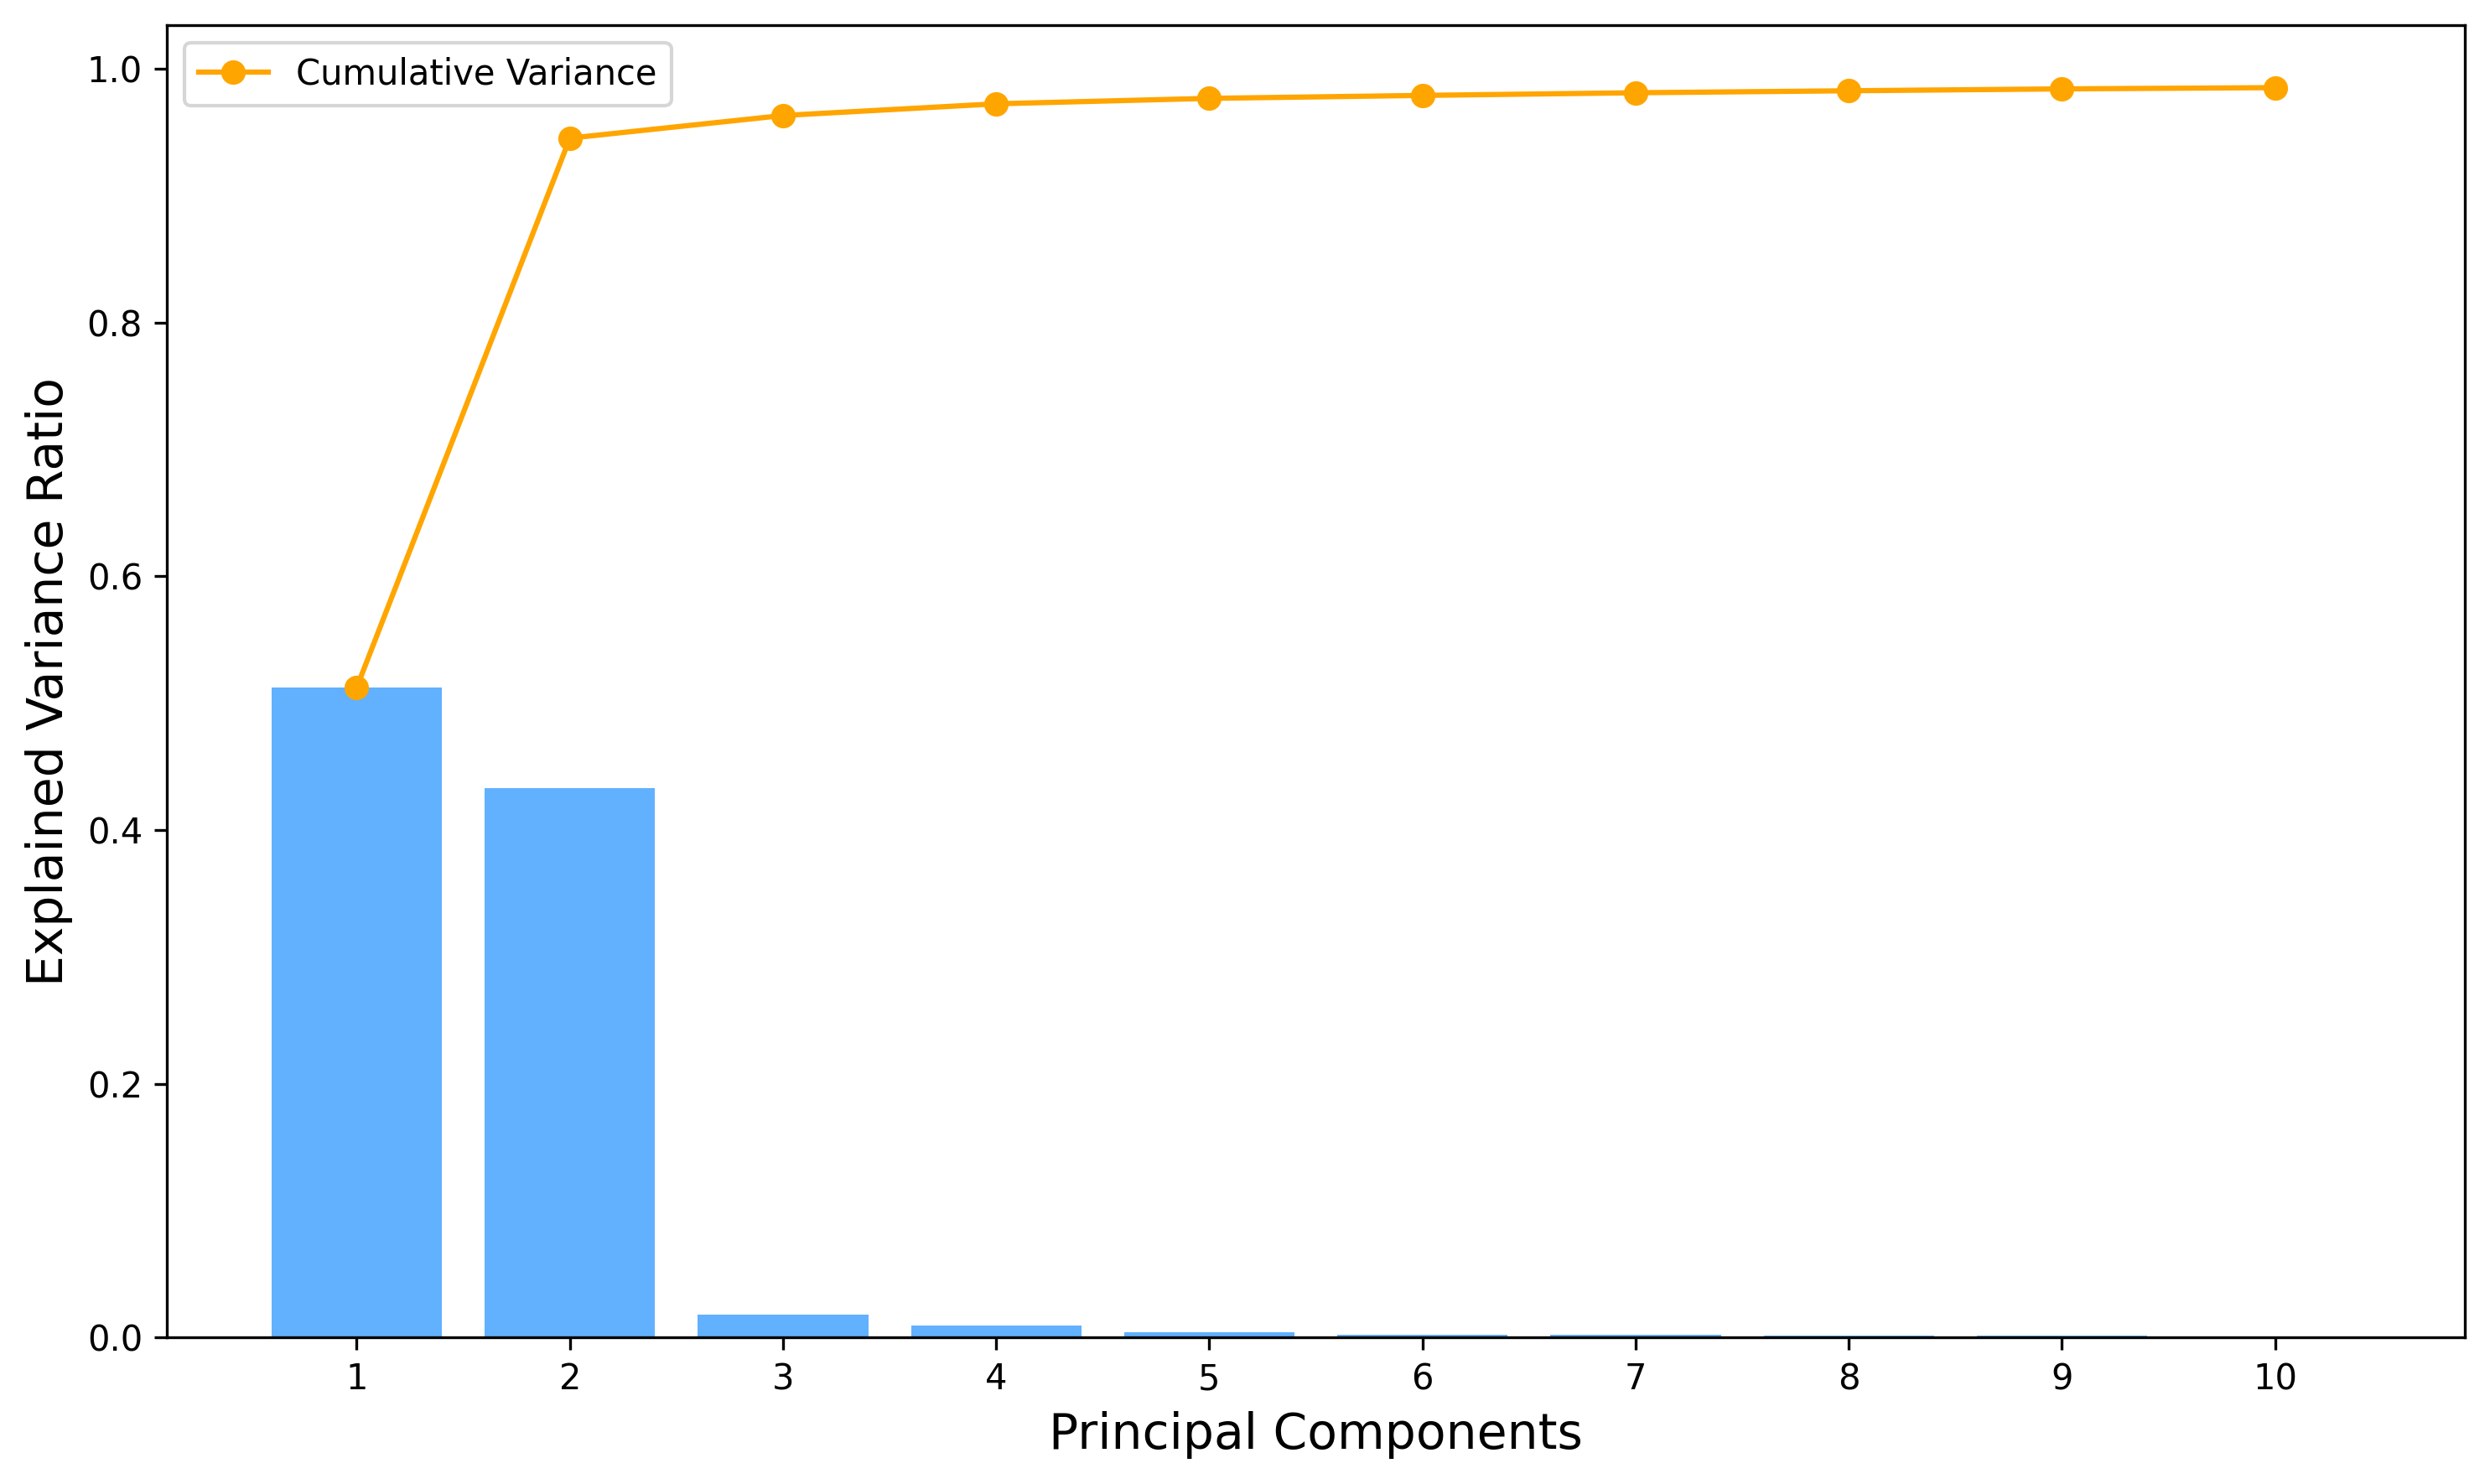

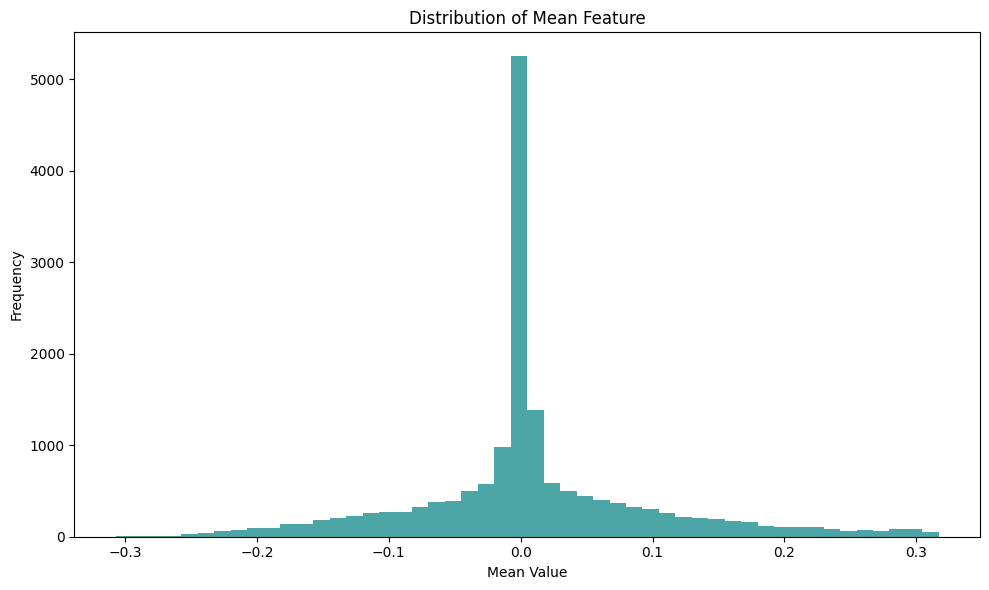

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# PCA Variance Plot
plt.figure(figsize=(10, 6), dpi=300)
pca = PCA(n_components=10)
pca_features = pca.fit_transform(scaled_features)
explained_variance = pca.explained_variance_ratio_

# Plot explained variance ratio
plt.bar(range(1, len(explained_variance) + 1), explained_variance, alpha=0.7, color='dodgerblue')
plt.plot(range(1, len(explained_variance) + 1), np.cumsum(explained_variance), marker='o', color='orange', label='Cumulative Variance')
#plt.title('Explained Variance by PCA Components', fontsize=16, fontweight='bold')
plt.xlabel('Principal Components', fontsize=14,fontname='Arial')
plt.ylabel('Explained Variance Ratio', fontsize=14, fontname='Arial')
plt.xticks(range(1, len(explained_variance) + 1))
plt.legend()
plt.tight_layout()
plt.savefig('expv.png', dpi=400)
plt.show()

# Statistical Features Distribution
# 1️⃣ Replace Infinite Values with NaN
stat_features.replace([np.inf, -np.inf], np.nan, inplace=True)

# 2️⃣ Fill NaN Values (Choose One Option)
stat_features = stat_features.fillna(stat_features.mean())

stat_features['mean'].plot(kind='hist', bins=50, alpha=0.7, color='teal', figsize=(10, 6), title='Distribution of Mean Feature')
plt.xlabel('Mean Value')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

# **Feature Selection**

# **Variance Threshold** 

In [31]:
from sklearn.feature_selection import VarianceThreshold,chi2

# Drop the target variable
features = final_dataset.drop('Column_101', axis=1)

# 1️⃣ Replace Infinite Values with NaN
features.replace([np.inf, -np.inf], np.nan, inplace=True)

# 2️⃣ Fill NaN Values (Choose One Option)
features = features.fillna(features.mean())  # Option 1: Fill with mean
# features = features.dropna()               # Option 2: Drop rows with NaN

# 3️⃣ Apply Variance Threshold for Feature Selection
threshold = 0.9  # Adjust as needed
vr = VarianceThreshold(threshold=threshold)
vr.fit(features)

# Get selected features
selected_features = features.columns[vr.get_support()]

print("Selected Features:", selected_features)
print('\n length:',len(selected_features))

Selected Features: Index(['Column_1', 'Column_2', 'Column_3', 'Column_4', 'Column_5', 'Column_6',
       'Column_7', 'Column_8', 'Column_9', 'Column_10',
       ...
       'fft_std_dev', 'fft_max', 'fft_energy', 'wavelet_coef_0',
       'impulse_factor', 'shape_factor', 'PC1', 'PC2', 'PC3', 'PC4'],
      dtype='object', length=113)

 length: 113


# **Anova F value**

In [32]:
from sklearn.preprocessing import LabelEncoder, StandardScaler
lbl = LabelEncoder()
std = StandardScaler()
y = final_dataset['Column_101']

In [34]:
features.shape, y.shape

((16983, 136), (16983,))

Selected features based on ANOVA F-Scores: ['std_dev', 'fft_max', 'fft_std_dev', 'rms', 'variance', 'iqr', 'fft_energy', 'energy', 'range', 'min', 'fft_mean', 'wavelet_coef_4', 'entropy', 'max', 'wavelet_coef_0']

ANOVA F-Scores:
             Feature      F_score
101         std_dev  3335.581990
115         fft_max  3262.773771
114     fft_std_dev  3075.993448
110             rms  3027.191419
111        variance  3001.232380
107             iqr  2959.832604
116      fft_energy  2865.742909
109          energy  2865.742909
108           range  2610.286771
102             min  1649.400256
113        fft_mean  1435.200102
121  wavelet_coef_4  1156.371282
112         entropy  1096.907360
103             max  1007.695094
117  wavelet_coef_0   901.825907


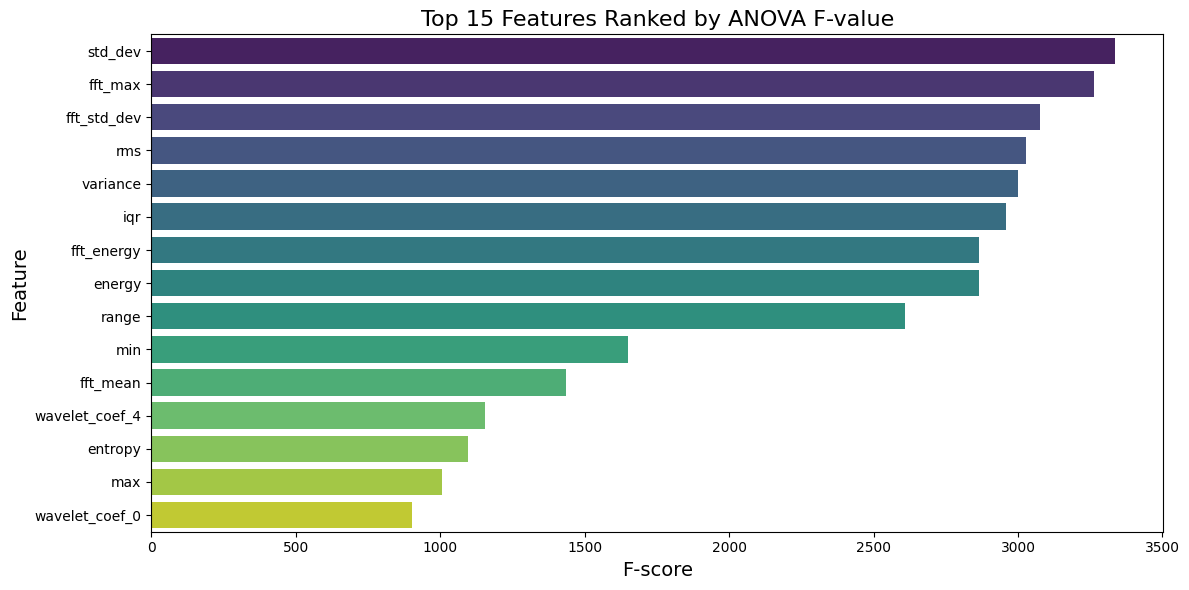

In [35]:
# 1️⃣ Replace Infinite Values with NaN
features.replace([np.inf, -np.inf], np.nan, inplace=True)

# 2️⃣ Fill NaN Values (Choose One Option)
features = features.fillna(features.mean()) 

from sklearn.feature_selection import f_classif

# Compute ANOVA F-values
f_values, p_values = f_classif(features, y)

# Create DataFrame of results
anova_results = pd.DataFrame({'Feature': features.columns, 'F_score': f_values})
anova_results = anova_results.sort_values(by='F_score', ascending=False)

# Print the selected features
selected_features = anova_results['Feature'].head(15).tolist()
print("Selected features based on ANOVA F-Scores:", selected_features)
print("\nANOVA F-Scores:\n", anova_results.head(15))

# Step 4: Sort features by F-score (descending)
feature_scores = anova_results.sort_values(by='F_score', ascending=False).head(15)

# Step 5: Plot
plt.figure(figsize=(12, 6))
sns.barplot(x='F_score', y='Feature', data=feature_scores, palette='viridis')
plt.title('Top 15 Features Ranked by ANOVA F-value', fontsize=16)
plt.xlabel('F-score', fontsize=14)
plt.ylabel('Feature', fontsize=14)
plt.tight_layout()
plt.show()

# **Correlation Analysis**

Selected features based on correlation threshold 0.8:
['std_dev', 'fft_max', 'fft_std_dev', 'rms', 'variance', 'iqr', 'fft_energy', 'energy', 'range', 'min', 'fft_mean', 'wavelet_coef_4', 'entropy', 'max', 'wavelet_coef_0']


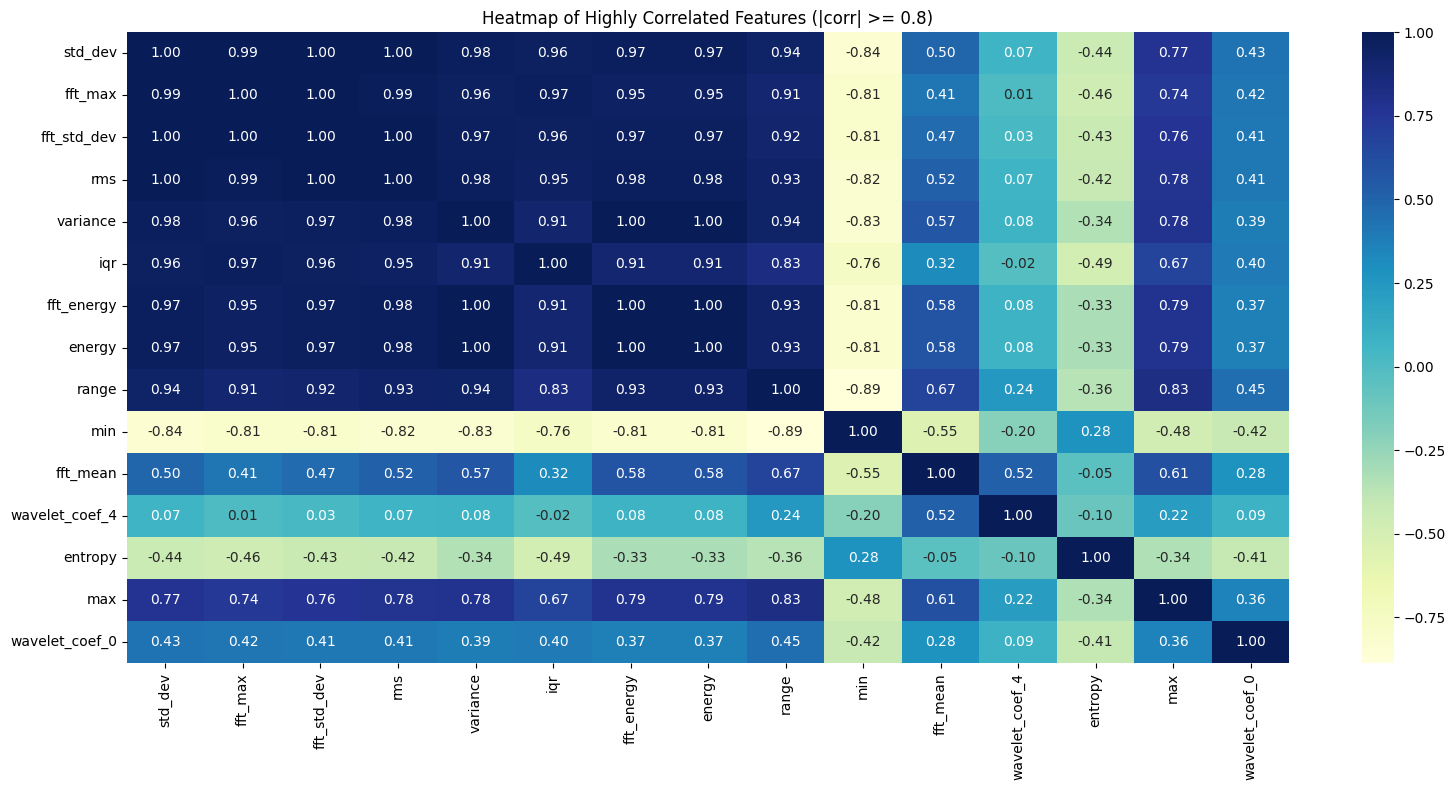

In [112]:
# Compute the correlation matrix
correlation_matrix = final_dataset[list(selected_features)].corr()

# Define a threshold for correlation
threshold = 0.8

# Identify highly correlated features
high_corr_pairs = correlation_matrix[(correlation_matrix.abs() >= threshold) & (correlation_matrix.abs() < 1)]
selected_features_ = high_corr_pairs.columns[high_corr_pairs.any()].tolist()

#selected_features.extend(['Label', 'Attack Type', 'Attack Tool'])

# Create a new DataFrame with only selected features
filtered_df = final_dataset[selected_features_]

# Display the selected features
print(f"Selected features based on correlation threshold {threshold}:\n{selected_features}")

# Plot the filtered heatmap
plt.figure(figsize=(16, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='YlGnBu', fmt=".2f")
plt.title(f"Heatmap of Highly Correlated Features (|corr| >= {threshold})")
plt.tight_layout()
plt.savefig('heatmap.png')
plt.show()

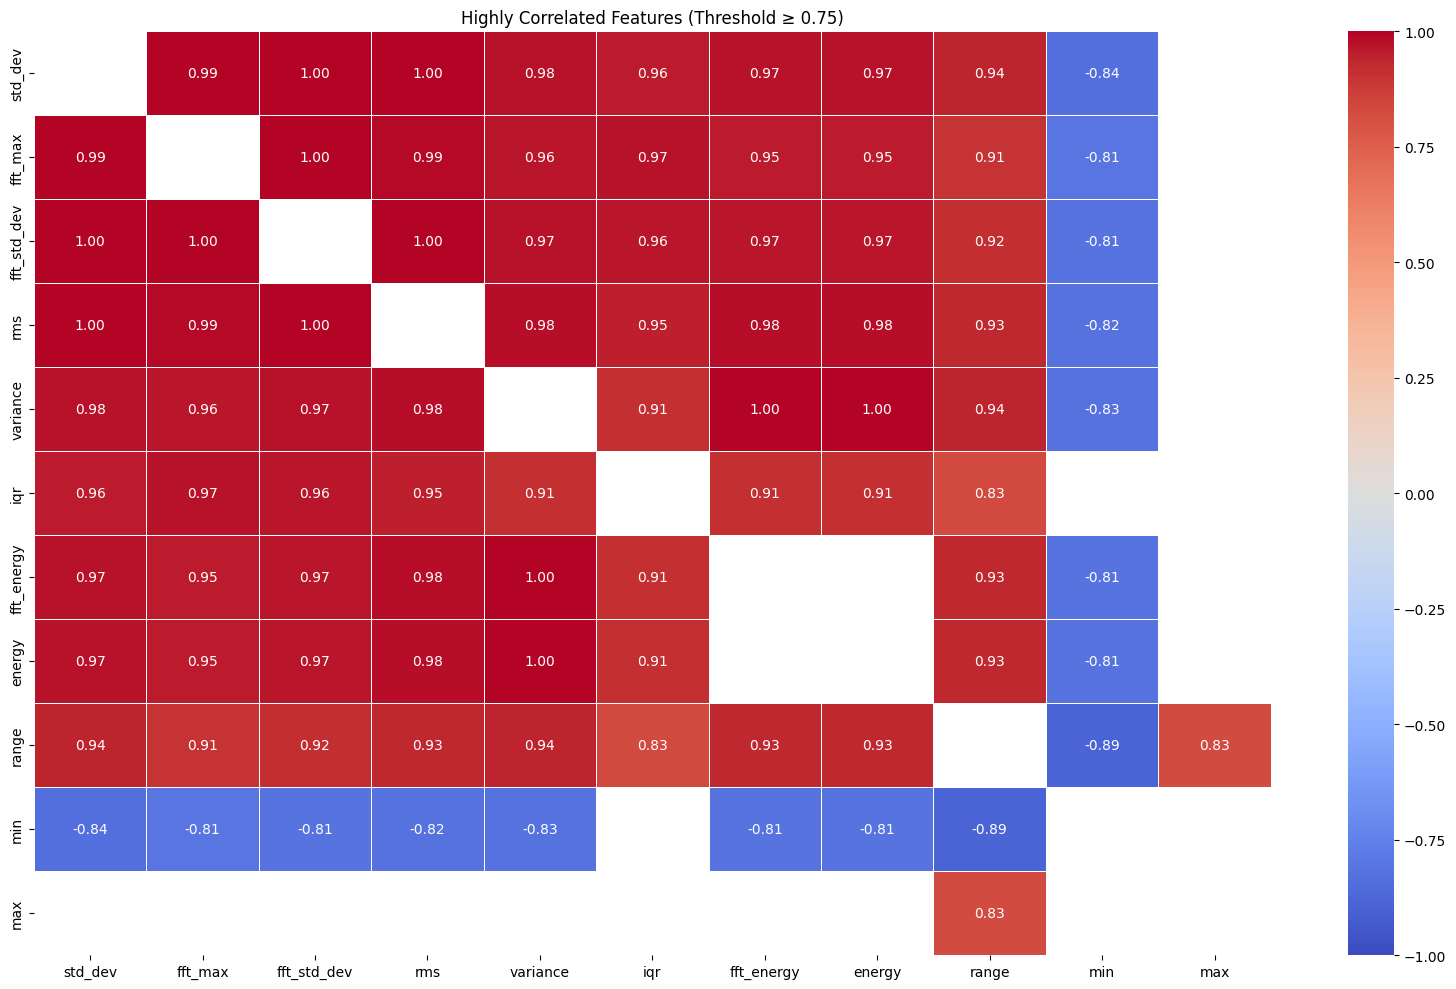

In [111]:
# Compute correlation matrix for selected high-variance features
correlation_matrix = final_dataset[selected_features].corr()

# Define threshold for high correlation (e.g., |0.75| or above)
threshold = 0.8

# Filter only highly correlated features
high_corr_features = correlation_matrix[(correlation_matrix.abs() >= threshold) & (correlation_matrix.abs() < 1.0)]

# Drop rows and columns that are entirely NaN (i.e., no strong correlation)
high_corr_features = high_corr_features.dropna(how='all', axis=0).dropna(how='all', axis=1)

# Plot heatmap only if there are highly correlated features
if not high_corr_features.empty:
    plt.figure(figsize=(16, 10))
    sns.heatmap(high_corr_features, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5, vmin=-1, vmax=1)
    plt.title('Highly Correlated Features (Threshold ≥ 0.75)')
    plt.tight_layout()
    plt.savefig('high_correlation_heatmap.png', dpi=300)
    plt.show()
else:
    print("No features with correlation above the threshold.")


# **Identify the highly correlated features with target variable**

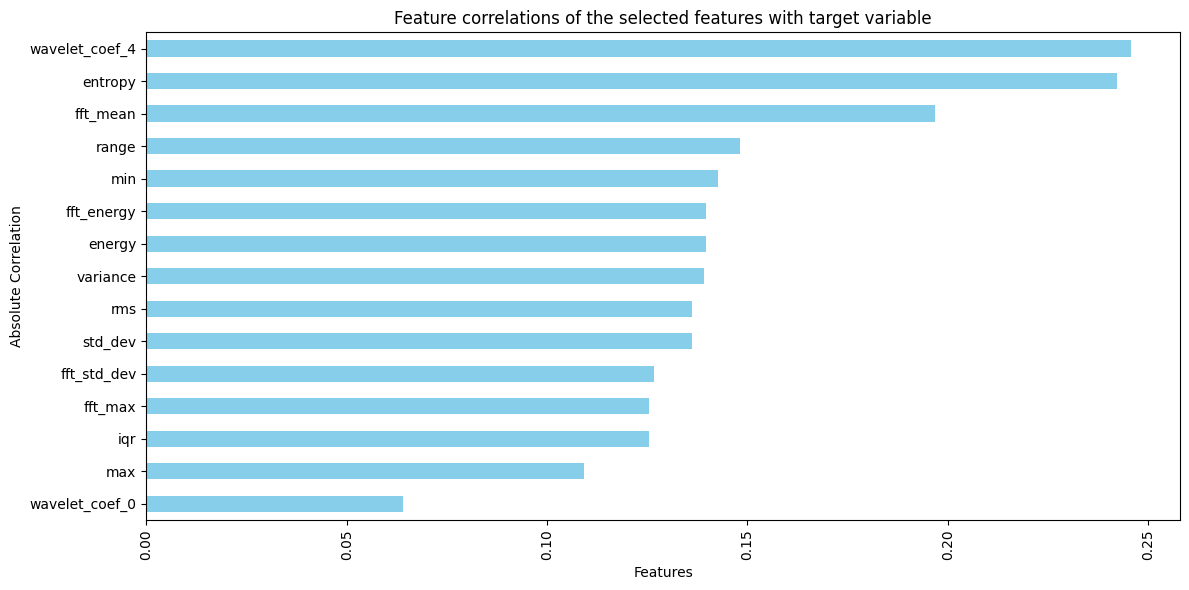

In [113]:
correlations = pd.concat([final_dataset[selected_features],final_dataset['Column_101']],axis=1).corr()['Column_101'].drop('Column_101')
sorted_correlations = correlations.abs().sort_values(ascending=True).head(20)


plt.figure(figsize=(12,6))
sorted_correlations.plot(kind='barh',color='skyblue',title='Feature correlations of the selected features with target variable')
plt.xlabel('Features')
plt.ylabel('Absolute Correlation')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

## **Split into feature and target + training_testing**

In [36]:
from sklearn.preprocessing import LabelEncoder, StandardScaler
lbl = LabelEncoder()
std = StandardScaler()

X = final_dataset.drop(['Column_101','wavelet_coef_0'],axis=1)

# Handle Inf and NaN values before training
X.replace([np.inf, -np.inf], np.nan, inplace=True)  # Convert infinite values to NaN
X.fillna(X.mean(), inplace=True)  # Replace NaN with mean values

# Standardize the data
X_scaled = std.fit_transform(X)

y = final_dataset['Column_101']

In [37]:
from sklearn.model_selection import train_test_split 
X_train, X_test, y_train, y_test = train_test_split(X_scaled,y,random_state=42,test_size=0.2)

In [38]:
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((13586, 135), (3397, 135), (13586,), (3397,))

# **Model apply**

# **Statistical Models**

Accuracy of RandomForest: 92.6111 %
Recall of RandomForest: 92.6111 %
Precision of RandomForest: 92.7515 %
F1 Score of RandomForest: 92.5787 %
ROC AUC of RandomForest: 99.7735 %
--------------------------------------------------
Accuracy of XGBoost: 95.3194 %
Recall of XGBoost: 95.3194 %
Precision of XGBoost: 95.3537 %
F1 Score of XGBoost: 95.3146 %
ROC AUC of XGBoost: 99.9119 %
--------------------------------------------------
Accuracy of ExtraTrees: 88.3427 %
Recall of ExtraTrees: 88.3427 %
Precision of ExtraTrees: 88.5485 %
F1 Score of ExtraTrees: 88.3096 %
ROC AUC of ExtraTrees: 99.6089 %
--------------------------------------------------
Accuracy of SVM: 78.7754 %
Recall of SVM: 78.7754 %
Precision of SVM: 79.8398 %
F1 Score of SVM: 78.3029 %
ROC AUC of SVM: 99.3964 %
--------------------------------------------------
Accuracy of MLP: 92.1401 %
Recall of MLP: 92.1401 %
Precision of MLP: 92.1532 %
F1 Score of MLP: 92.1135 %
ROC AUC of MLP: 99.8006 %
-------------------------------

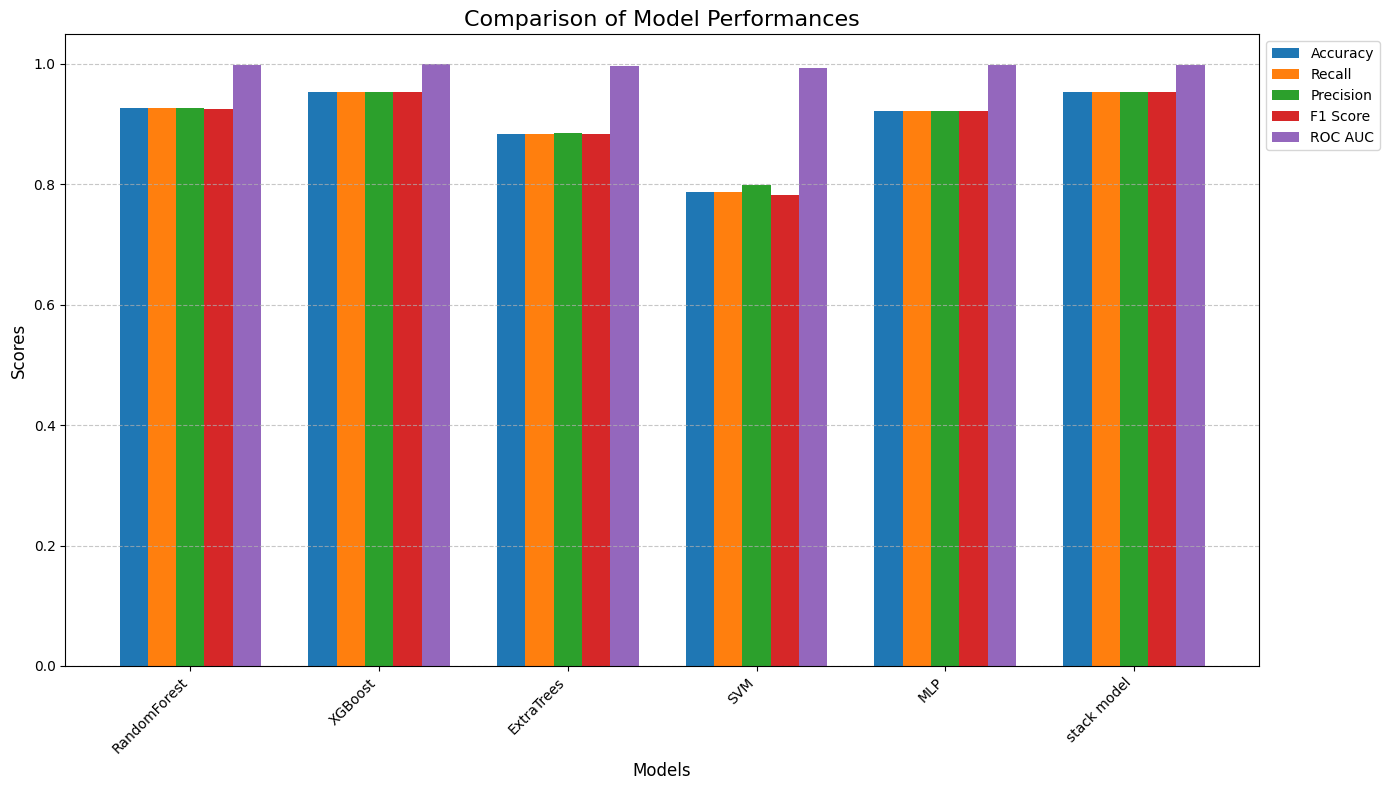


Performance Comparison Table:
          Model  Accuracy    Recall  Precision  F1 Score   ROC AUC
0  RandomForest  0.926111  0.926111   0.927515  0.925787  0.997735
1       XGBoost  0.953194  0.953194   0.953537  0.953146  0.999119
2    ExtraTrees  0.883427  0.883427   0.885485  0.883096  0.996089
3           SVM  0.787754  0.787754   0.798398  0.783029  0.993964
4           MLP  0.921401  0.921401   0.921532  0.921135  0.998006
5   stack model  0.952605  0.952605   0.953290  0.952645  0.998127


In [117]:
from sklearn.svm import SVC
from sklearn.ensemble import StackingClassifier
from sklearn.neural_network import MLPClassifier


rf = RandomForestClassifier(random_state = 42, criterion='gini')
xgb = XGBClassifier(random_state=42)
ext = ExtraTreesClassifier(random_state=42)
sv = SVC(kernel='rbf', probability=True)
mlp = MLPClassifier(hidden_layer_sizes=(100,),max_iter = 500,random_state=42)


# Stacking Classifier (Combining multiple models)
stacking_model = StackingClassifier(
    estimators=[
        ('xgb', xgb),
        ('svm', sv),
    ],
    final_estimator=RandomForestClassifier(n_estimators=100, random_state=42)
)



models = {'RandomForest': rf,
          'XGBoost': xgb,
          'ExtraTrees':ext,
          'SVM': sv,
          'MLP': mlp,
          'stack model': stacking_model}


model_names = []
accuracies = []
recalls = []
precisions = []
f1_scores = []
roc_auc_scores = []


# Check if the target variable is multiclass
is_multiclass = len(np.unique(y)) > 2

if is_multiclass:
    # Binarize the output for multiclass classification
    y_test_bin = label_binarize(y_test, classes=np.unique(y))
    n_classes = y_test_bin.shape[1]

# Train models and evaluate performance
for key, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    # Calculate accuracy, recall, precision, and F1 score
    acc = accuracy_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred, average='weighted')
    precision = precision_score(y_test, y_pred, average='weighted')
    f1 = f1_score(y_test, y_pred, average='weighted')

    # Handle ROC AUC calculation for binary vs. multiclass
    if is_multiclass:
        # Predict probabilities for all classes
        y_prob = model.predict_proba(X_test)

        # Compute micro-average ROC AUC
        fpr, tpr, _ = roc_curve(y_test_bin.ravel(), y_prob.ravel())
        roc_auc = auc(fpr, tpr)
    else:
        # For binary classification, compute ROC AUC directly
        y_prob = model.predict_proba(X_test)[:, 1]
        fpr, tpr, _ = roc_curve(y_test, y_prob)
        roc_auc = auc(fpr, tpr)

    # Store metrics
    model_names.append(key)
    accuracies.append(acc)
    recalls.append(recall)
    precisions.append(precision)
    f1_scores.append(f1)
    roc_auc_scores.append(roc_auc)

    # Print metrics
    print(f"Accuracy of {key}: {acc * 100:.4f} %")
    print(f"Recall of {key}: {recall * 100:.4f} %")
    print(f"Precision of {key}: {precision * 100:.4f} %")
    print(f"F1 Score of {key}: {f1 * 100:.4f} %")
    print(f"ROC AUC of {key}: {roc_auc * 100:.4f} %")
    print("-" * 50)

# Create a DataFrame for comparison
performance_df = pd.DataFrame({
    "Model": model_names,
    "Accuracy": accuracies,
    "Recall": recalls,
    "Precision": precisions,
    "F1 Score": f1_scores,
    "ROC AUC": roc_auc_scores
})

# Plot comparison chart
metrics = ["Accuracy", "Recall", "Precision", "F1 Score", "ROC AUC"]
x = np.arange(len(model_names))  # X-axis positions for the models
width = 0.15  # Width of the bars

fig, ax = plt.subplots(figsize=(14, 8))
for i, metric in enumerate(metrics):
    ax.bar(x + i * width, performance_df[metric], width, label=metric)

ax.set_xlabel("Models", fontsize=12)
ax.set_ylabel("Scores", fontsize=12)
ax.set_title("Comparison of Model Performances", fontsize=16)
ax.set_xticks(x + width * (len(metrics) - 1) / 2)
ax.set_xticklabels(model_names, rotation=45, ha="right")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1), fontsize=10)
ax.grid(axis="y", linestyle="--", alpha=0.7)

plt.tight_layout()
plt.show()

# Display the performance DataFrame
print("\nPerformance Comparison Table:")
print(performance_df)

# **Confusion Matrix**

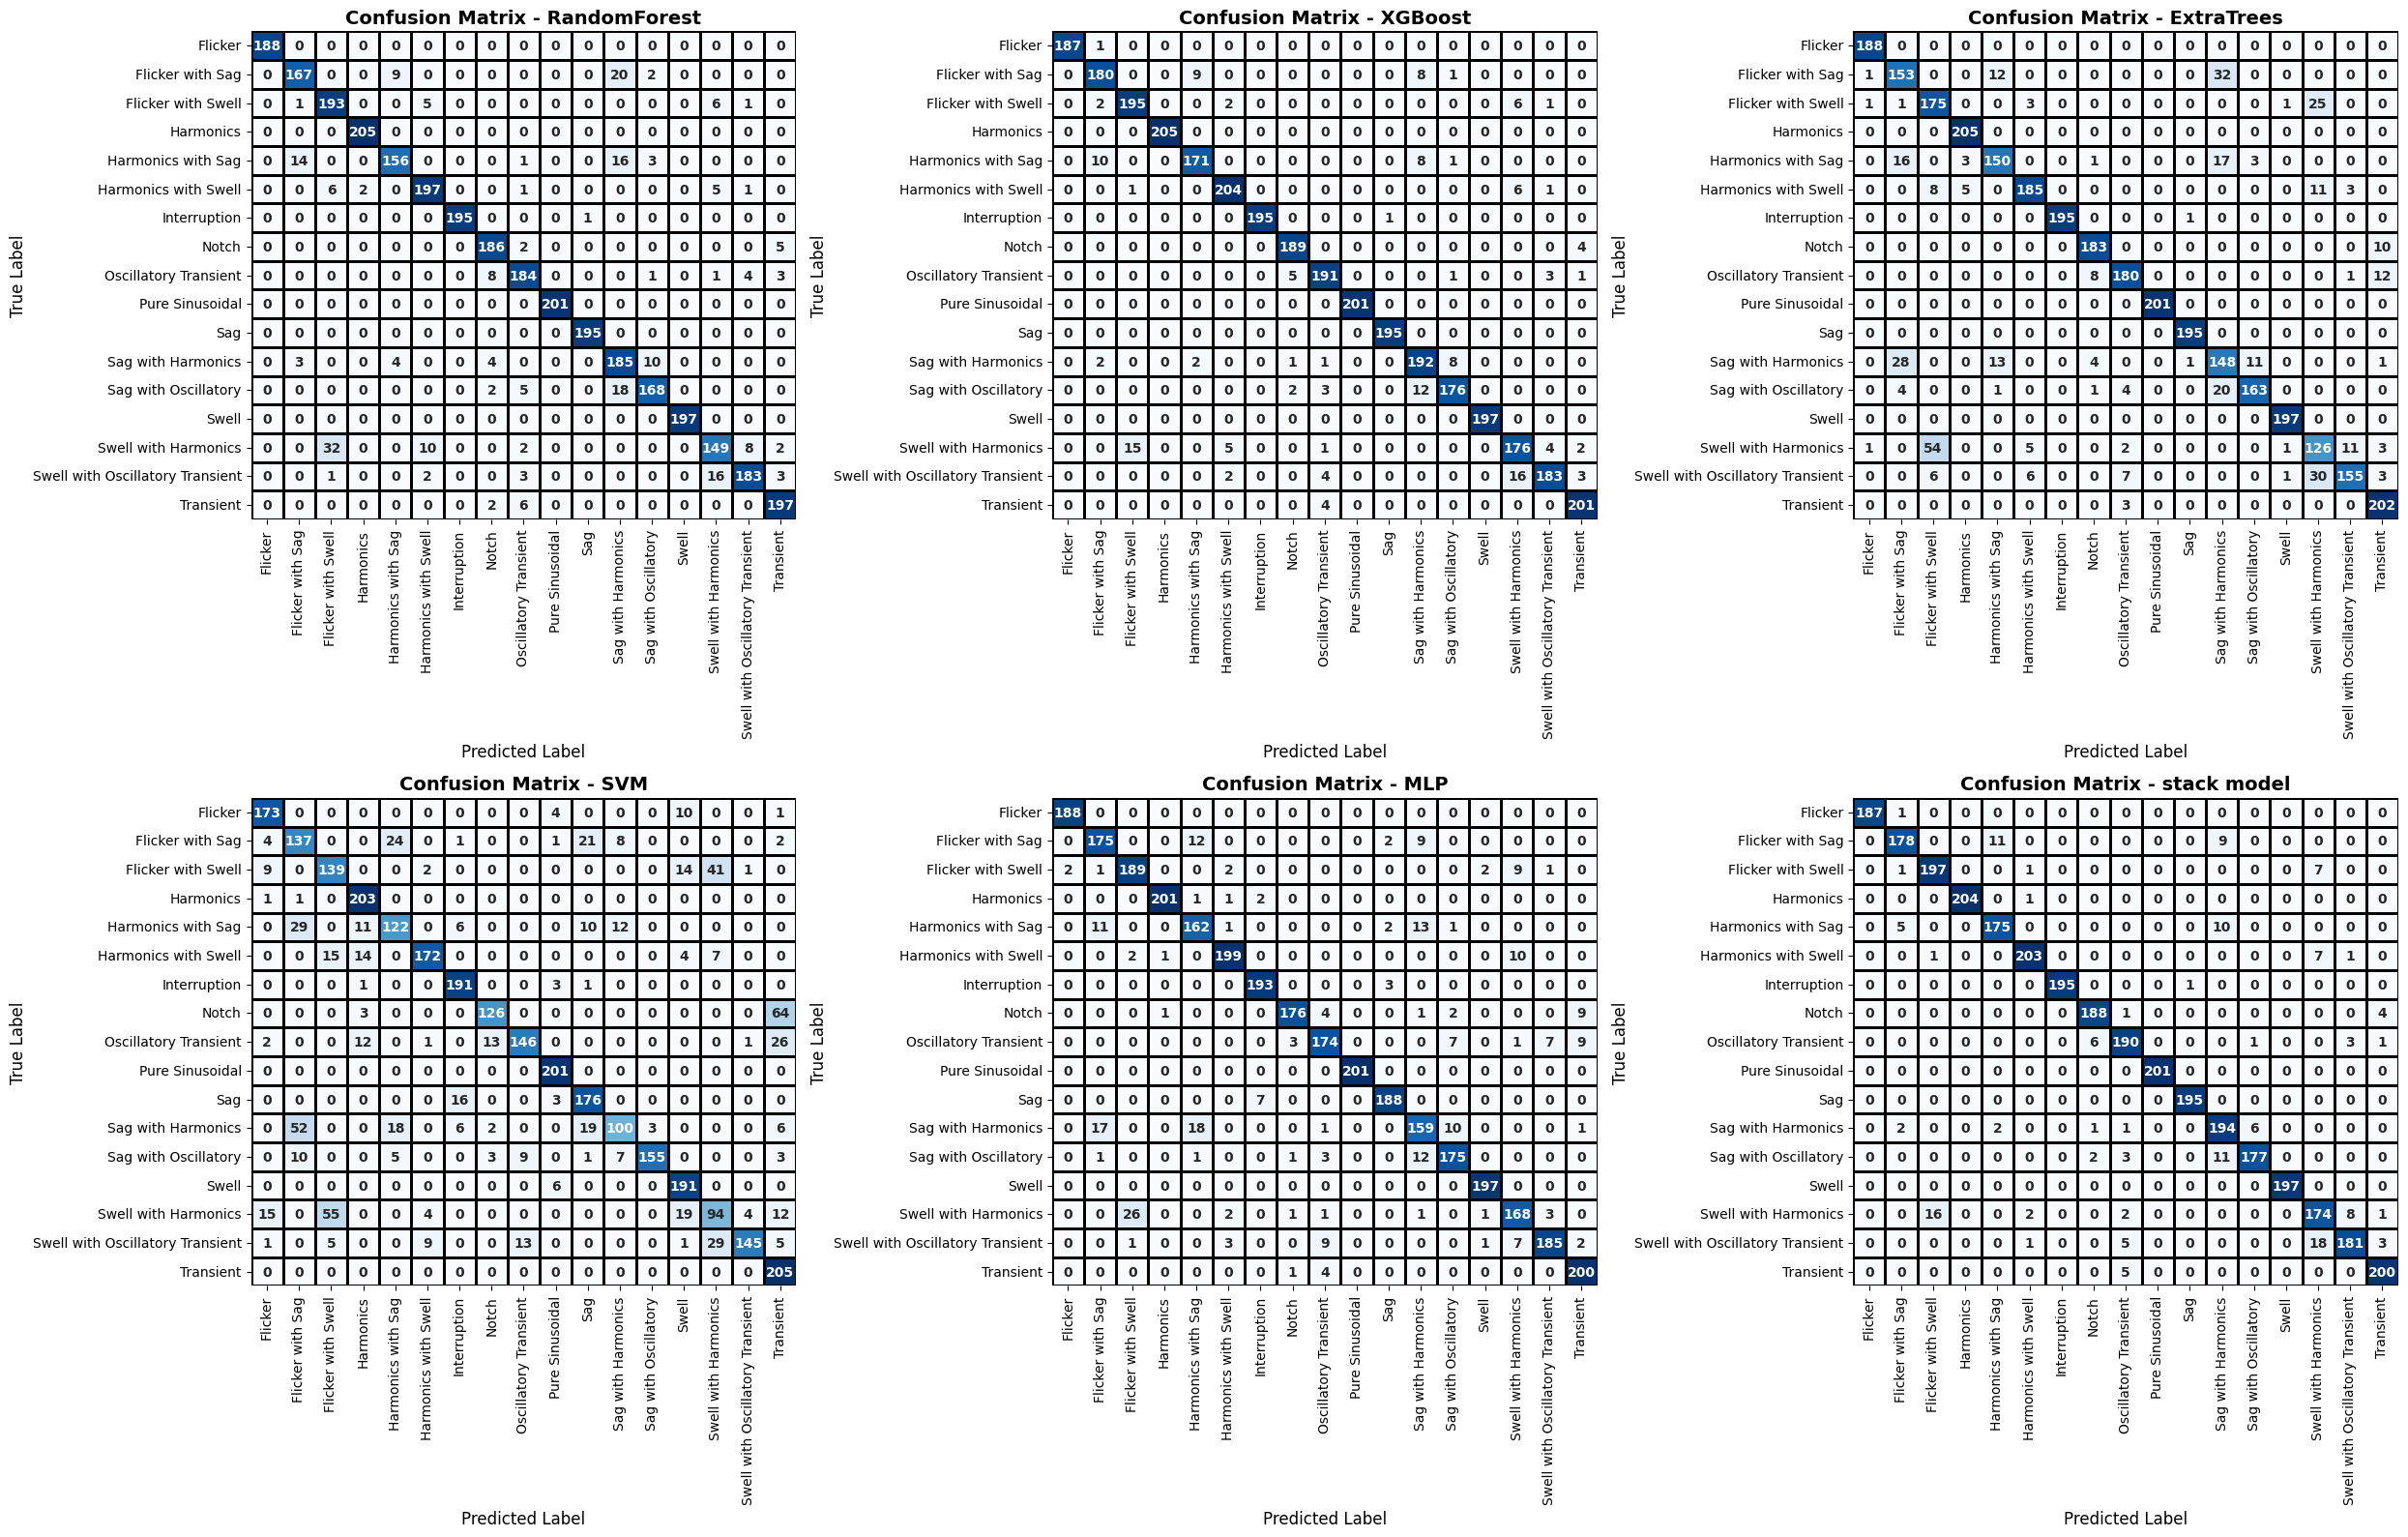

In [118]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# Class Labels
class_labels = ['Flicker', 'Flicker with Sag', 'Flicker with Swell', 'Harmonics',
                'Harmonics with Sag', 'Harmonics with Swell', 'Interruption',
                'Notch', 'Oscillatory Transient', 'Pure Sinusoidal', 'Sag',
                'Sag with Harmonics', 'Sag with Oscillatory', 'Swell',
                'Swell with Harmonics', 'Swell with Oscillatory Transient', 'Transient']

# Increase figure size for better clarity
fig, axes = plt.subplots(2, 3, figsize=(25, 16))  # Larger figure size
axes = axes.flatten()

for i, (key, model) in enumerate(models.items()):
    #model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    cm = confusion_matrix(y_test, y_pred)

    # Create heatmap with larger, clearer annotations
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_labels, 
                yticklabels=class_labels, ax=axes[i], annot_kws={"size": 10, 'weight': 'bold'}, linewidths=1, linecolor='black',cbar=False)

    axes[i].set_title(f"Confusion Matrix - {key}", fontsize=14, fontweight="bold")
    axes[i].set_xlabel("Predicted Label", fontsize=12)
    axes[i].set_ylabel("True Label", fontsize=12)
    axes[i].tick_params(axis='x', rotation=90)  # Rotate x-axis labels for better visibility
    axes[i].tick_params(axis='y', rotation=0)   # Keep y-axis labels readable

# Hide unused subplots if models are fewer than 6
for j in range(i + 1, len(axes)):
    axes[j].axis("off")

plt.tight_layout()

# Save as high-resolution image
plt.savefig("confusion_matrices_high_res.png", dpi=600, bbox_inches="tight")  # High-resolution PNG
plt.show()



# **Explainability of XGBoost**

In [119]:
from xgboost import plot_importance

xgb = XGBClassifier(random_state=42)
xgb.fit(X_train,y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              gamma=None, grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=None, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=None, n_jobs=None,
              num_parallel_tree=None, objective='multi:softprob', ...)

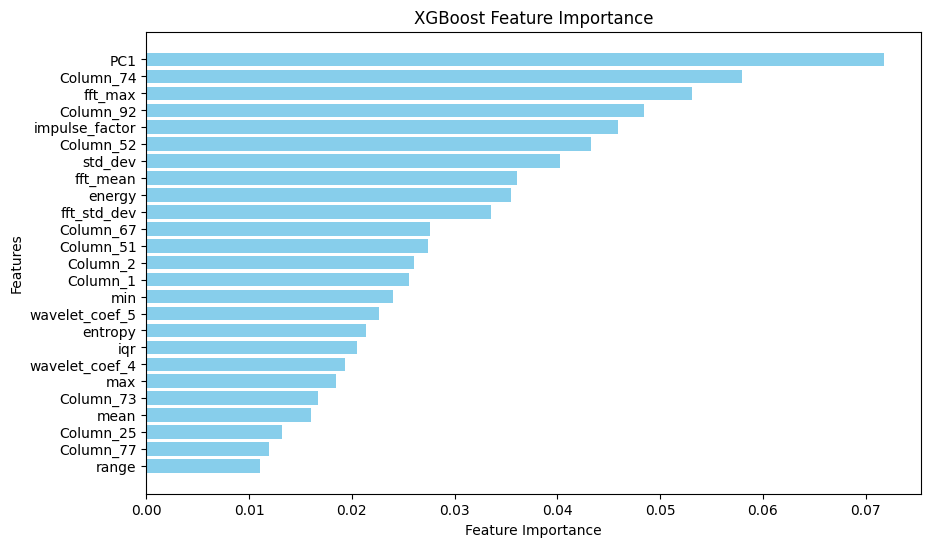

In [120]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Get feature importances
feature_importance = xgb.feature_importances_

# Create a DataFrame for visualization
feature_names = X.columns  # Ensure X_train is a DataFrame
importance_df = pd.DataFrame({"Feature": feature_names, "Importance": feature_importance})

# Sort by importance
importance_df = importance_df.sort_values(by="Importance", ascending=False).head(25)

# Plot feature importances
plt.figure(figsize=(10, 6))
plt.barh(importance_df["Feature"], importance_df["Importance"], color="skyblue")
plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("XGBoost Feature Importance")
plt.gca().invert_yaxis()
plt.savefig('xgboost feature importance.png',dpi=400)
plt.show()


In [121]:
X_test_df = pd.DataFrame(X_test,columns=X.columns)

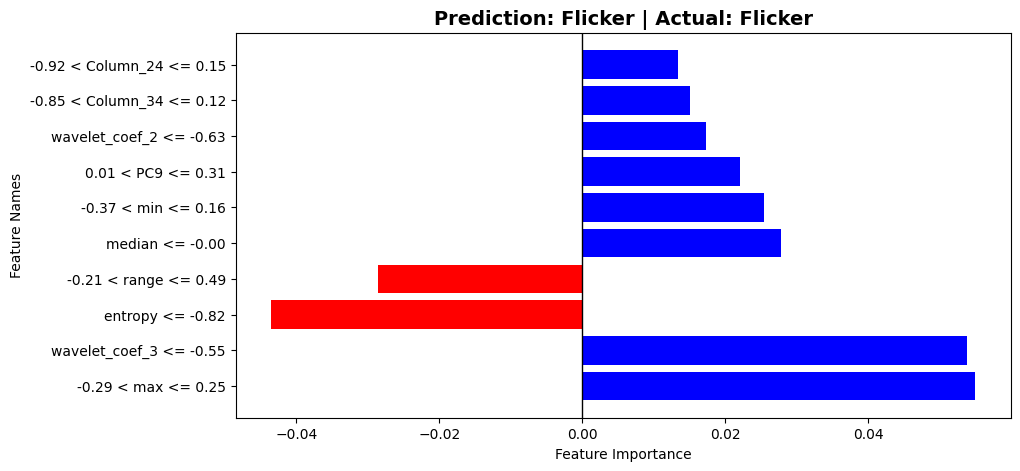

In [39]:
from lime.lime_tabular import LimeTabularExplainer
import numpy as np
import matplotlib.pyplot as plt

# Initialize LIME explainer
explainer = LimeTabularExplainer(
    training_data=np.array(X_train),
    feature_names=X.columns,
    class_names=['Flicker', 'Flicker with Sag', 'Flicker with Swell', 'Harmonics',
                 'Harmonics with Sag', 'Harmonics with Swell', 'Interruption',
                 'Notch', 'Oscillatory Transient', 'Pure Sinusoidal', 'Sag',
                 'Sag with Harmonics', 'Sag with Oscillatory', 'Swell',
                 'Swell with Harmonics', 'Swell with Oscillatory Transient', 'Transient'],
    mode="classification"
)

# Select a test instance to explain
i = 10  # Choose an index of the test sample
exp = explainer.explain_instance(X_test_df.iloc[i], xgb.predict_proba)

# Extract LIME explanation
lime_exp = exp.as_list()

# Convert explanation to a dictionary
feature_names = [f[0] for f in lime_exp]
feature_importances = [f[1] for f in lime_exp]

# Get the predicted class
predicted_class_index = np.argmax(exp.predict_proba)
predicted_class_name = explainer.class_names[predicted_class_index]

# Get the actual class
actual_class_index = y_test.iloc[i]
actual_class_name = explainer.class_names[actual_class_index]

# Create an interactive bar chart
plt.figure(figsize=(10, 5))
plt.barh(feature_names, feature_importances, color=['blue' if val > 0 else 'red' for val in feature_importances])
plt.xlabel("Feature Importance")
plt.ylabel("Feature Names")
plt.title(f"Prediction: {predicted_class_name} | Actual: {actual_class_name}", fontsize=14, fontweight="bold")
plt.axvline(0, color='black', linewidth=1)  # Add a reference line
plt.show()


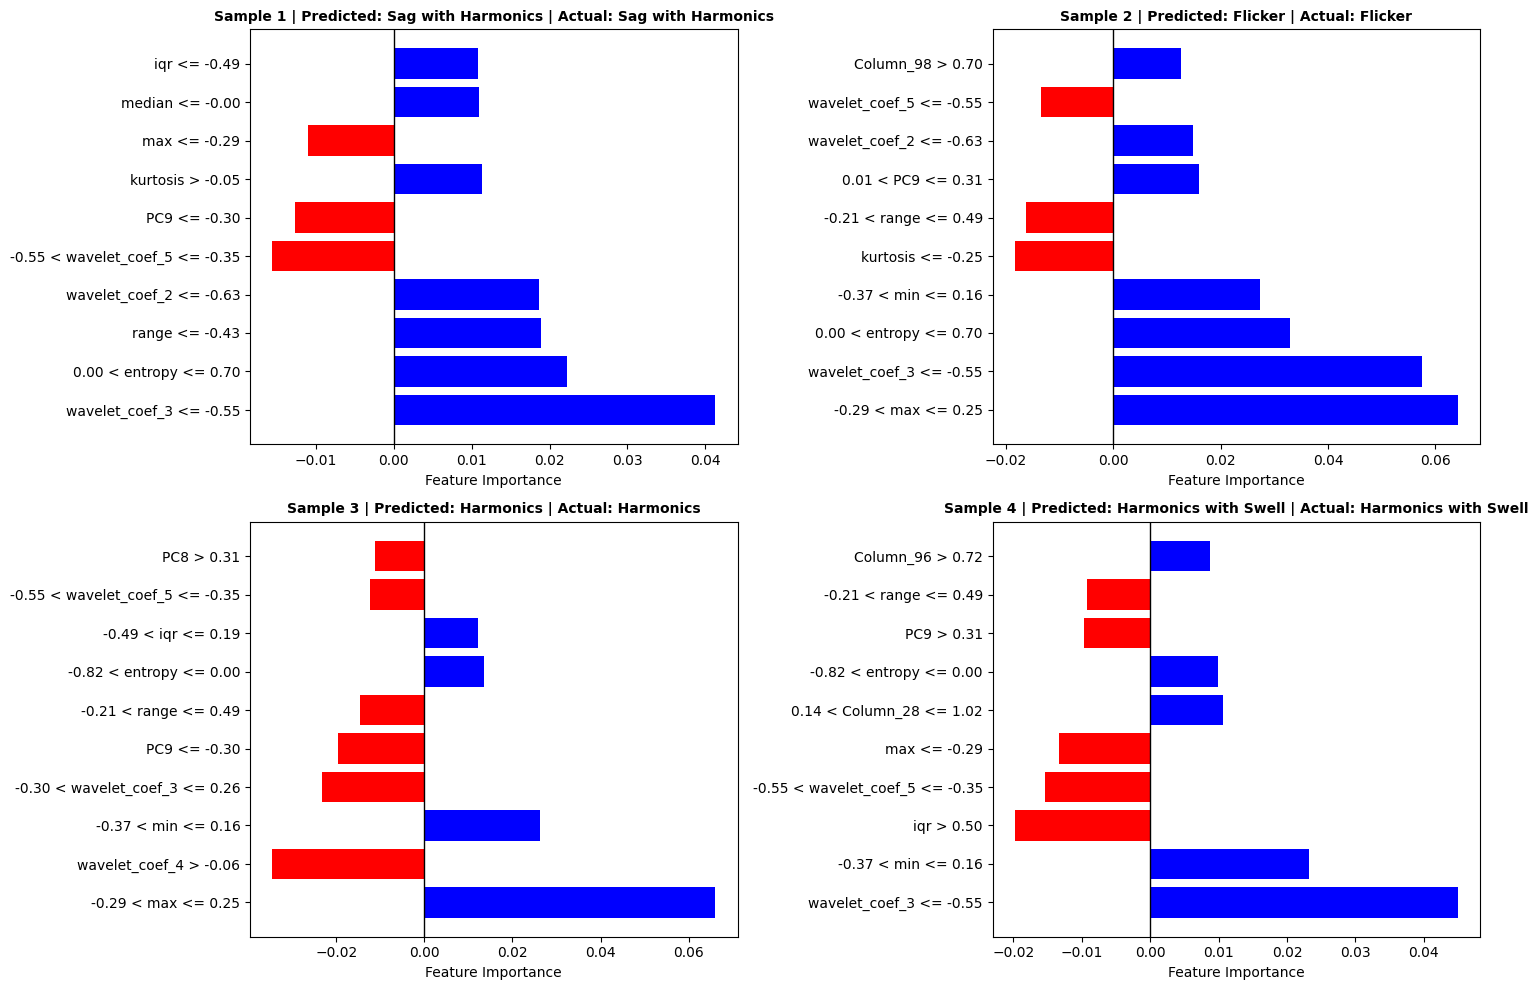

In [122]:
import matplotlib.pyplot as plt
import numpy as np
from lime.lime_tabular import LimeTabularExplainer

# Initialize LIME explainer
explainer = LimeTabularExplainer(
    training_data=np.array(X_train),
    feature_names=X.columns,
    class_names=['Flicker', 'Flicker with Sag', 'Flicker with Swell', 'Harmonics',
                 'Harmonics with Sag', 'Harmonics with Swell', 'Interruption',
                 'Notch', 'Oscillatory Transient', 'Pure Sinusoidal', 'Sag',
                 'Sag with Harmonics', 'Sag with Oscillatory', 'Swell',
                 'Swell with Harmonics', 'Swell with Oscillatory Transient', 'Transient'],
    mode="classification"
)

# Select at least 6 samples for interpretation
num_samples = 4
sample_indices = np.random.choice(len(X_test), num_samples, replace=False)  # Randomly select 6 test samples

# Create subplots for visualization
fig, axes = plt.subplots(2, 2, figsize=(15, 10))  # 2 rows, 3 columns
axes = axes.flatten()

for idx, sample_index in enumerate(sample_indices):
    exp = explainer.explain_instance(X_test_df.iloc[sample_index], xgb.predict_proba)
    
    # Extract feature importance values
    lime_exp = exp.as_list()
    feature_names = [f[0] for f in lime_exp]
    feature_importances = [f[1] for f in lime_exp]

    # Get predicted & actual class names
    predicted_class_index = np.argmax(exp.predict_proba)
    predicted_class_name = explainer.class_names[predicted_class_index]
    
    actual_class_index = y_test.iloc[sample_index]
    actual_class_name = explainer.class_names[actual_class_index]

    # Plot feature importance for this sample
    axes[idx].barh(feature_names, feature_importances, color=['blue' if val > 0 else 'red' for val in feature_importances])
    axes[idx].set_xlabel("Feature Importance")
    axes[idx].set_title(f"Sample {idx+1} | Predicted: {predicted_class_name} | Actual: {actual_class_name}", fontsize=10, fontweight="bold")
    axes[idx].axvline(0, color='black', linewidth=1)  # Add a reference line

# Adjust layout
plt.tight_layout()
plt.savefig('lime interpretability.png',dpi=300)
plt.show()


# **Deep Learning**

In [39]:
from tensorflow.keras.layers import Dense, LSTM, Bidirectional, Dropout
from tensorflow.keras.models import Sequential
from tensorflow.keras.regularizers import l2
from keras.callbacks import Callback

# **ANN**

In [55]:
# build ANN model

model = Sequential()
model.add(Dense(units = 128, activation='relu',input_shape=(X_train.shape[1],)))
model.add(Dense(units= 64,activation='relu',kernel_regularizer = l2(0.0001)))
model.add(Dropout(0.5))
model.add(Dense(units=17,activation='softmax',kernel_regularizer=l2(0.0001)))
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 128)            │        17,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 17)             │         1,105 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 26,769 (104.57 KB)

 Trainable params: 26,769 (104.57 KB)

 Non-trainable params: 0 (0.00 B)

In [56]:
model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])


# Define a custom callback to stop training when validation accuracy >= 90%
class StopAt90PercentAccuracy(Callback):
    def on_epoch_end(self, epoch, logs=None):
        val_accuracy = logs.get('val_accuracy')
        if val_accuracy is not None and val_accuracy >= 0.95:
            print(f"\nStopping training as validation accuracy reached {val_accuracy:.2f}")
            self.model.stop_training = True

# Instantiate the custom callback
stop_at_90 = StopAt90PercentAccuracy()

# Train the model with the custom callback
history = model.fit(X_train, y_train, 
                    batch_size=32, 
                    validation_split=0.2, 
                    epochs=500, 
                    callbacks=[stop_at_90])

Epoch 1/500
340/340 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.2710 - loss: 2.3092 - val_accuracy: 0.6472 - val_loss: 1.1325
Epoch 2/500
340/340 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.5536 - loss: 1.2917 - val_accuracy: 0.7528 - val_loss: 0.7775
Epoch 3/500
340/340 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6669 - loss: 0.9569 - val_accuracy: 0.7862 - val_loss: 0.6346
Epoch 4/500
340/340 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7182 - loss: 0.8133 - val_accuracy: 0.8032 - val_loss: 0.5745
Epoch 5/500
340/340 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7442 - loss: 0.7297 - val_accuracy: 0.8194 - val_loss: 0.5474
Epoch 6/500
340/340 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7650 - loss: 0.6762 - val_accuracy: 0.8252 - val_loss: 0.5032
Epoch 7/500
340/340 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7921 - loss: 0.6220 - val_accuracy: 0.8241 - val_loss: 0.4973
Epoch 8/500
340/340 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7953 - loss: 0.6036 - val_accu

In [57]:
model.evaluate(X_test,y_test)

107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9265 - loss: 0.3452


[0.3453192114830017, 0.9287606477737427]

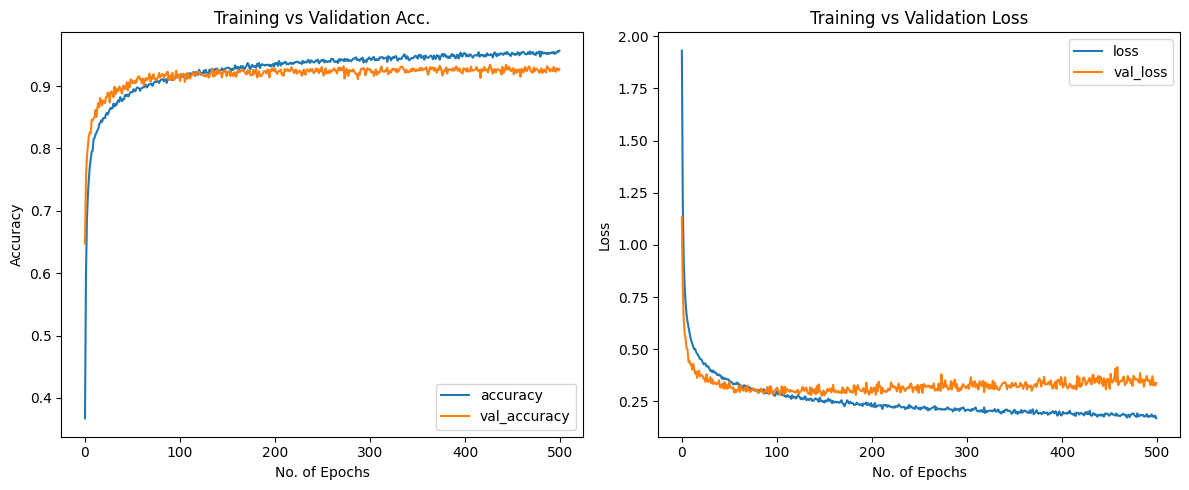

In [58]:
fig,ax = plt.subplots(1,2,figsize=(12,5))
pd.DataFrame(history.history)[['accuracy','val_accuracy']].plot(ax=ax[0])
ax[0].set_xlabel('No. of Epochs')
ax[0].set_ylabel('Accuracy')
ax[0].set_title('Training vs Validation Acc.')


pd.DataFrame(history.history)[['loss','val_loss']].plot(ax=ax[1])
ax[1].set_xlabel('No. of Epochs')
ax[1].set_ylabel('Loss')
ax[1].set_title('Training vs Validation Loss')

plt.tight_layout()
plt.savefig('ANN performance.png',dpi=400)
plt.show()

In [59]:
# Check if the target variable is multiclass
is_multiclass = len(np.unique(y)) > 2

if is_multiclass:
    # Binarize the output for multiclass classification
    y_test_bin = label_binarize(y_test, classes=np.unique(y))
    n_classes = y_test_bin.shape[1]


# Class Labels
class_labels = ['Flicker', 'Flicker with Sag', 'Flicker with Swell', 'Harmonics',
                'Harmonics with Sag', 'Harmonics with Swell', 'Interruption',
                'Notch', 'Oscillatory Transient', 'Pure Sinusoidal', 'Sag',
                'Sag with Harmonics', 'Sag with Oscillatory', 'Swell',
                'Swell with Harmonics', 'Swell with Oscillatory Transient', 'Transient']



# Convert predicted probabilities to class labels (index of highest probability)
predicted_classes = np.argmax(model.predict(X_test), axis=1)

print(f"accuracy score : {accuracy_score(y_test,predicted_classes):.6f}")
print(f"precision score : {precision_score(y_test,predicted_classes,average='weighted'):.6f}")
print(f"recall score : {recall_score(y_test,predicted_classes,average='weighted'):.6f}")
print(f"f1 score : {f1_score(y_test,predicted_classes,average='weighted'):.6f}")



    # Handle ROC AUC calculation for binary vs. multiclass
if is_multiclass:
        # Predict probabilities for all classes
    y_prob = model.predict(X_test)

        # Compute micro-average ROC AUC
    fpr, tpr, _ = roc_curve(y_test_bin.ravel(), y_prob.ravel())
    roc_auc = auc(fpr, tpr)
    print(f" Roc Auc score : {roc_auc:.6f}")
else:
        # For binary classification, compute ROC AUC directly
    y_prob = model.predict(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_auc = auc(fpr, tpr)

107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
accuracy score : 0.928761
precision score : 0.929326
recall score : 0.928761
f1 score : 0.928221
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
 Roc Auc score : 0.997418


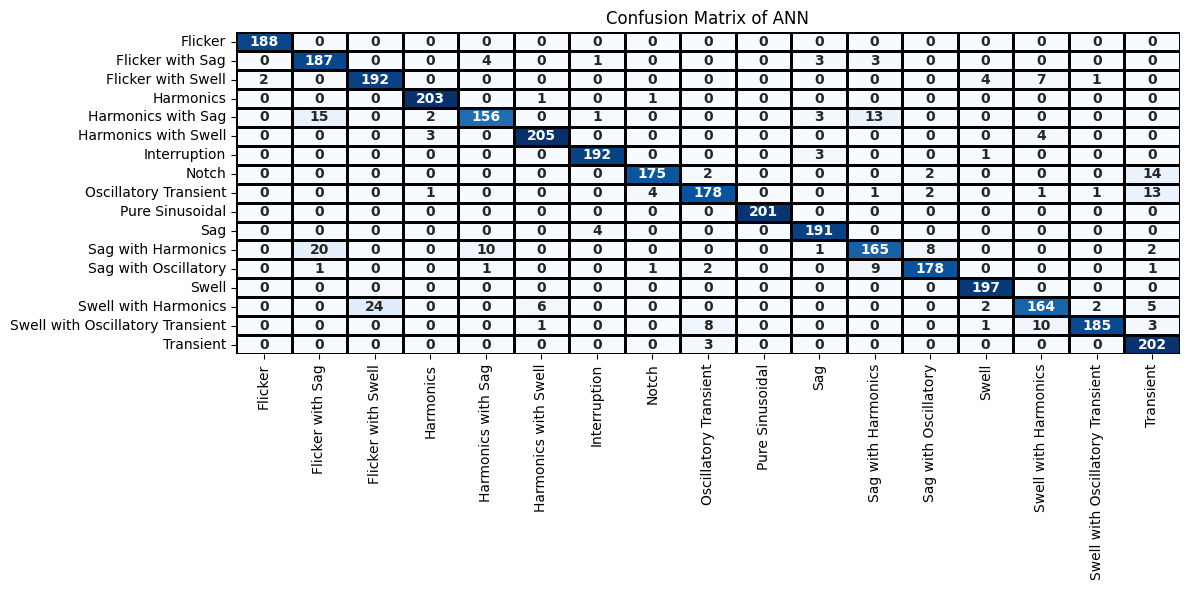

In [46]:
cnf = confusion_matrix(y_test,predicted_classes)
plt.figure(figsize=(12,6))
# Create heatmap with larger, clearer annotations
sns.heatmap(cnf, annot=True, fmt="d", cmap="Blues", xticklabels=class_labels, 
                yticklabels=class_labels, annot_kws={"size": 10, 'weight': 'bold'}, linewidths=1, linecolor='black',cbar=False)

plt.title('Confusion Matrix of ANN')
plt.tight_layout()
plt.show()

# **LSTM**

In [ ]:
from sklearn.preprocessing import LabelBinarizer
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, LSTM, Dropout

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.fit_transform(X_test)

X_train_lstm = X_train_scaled.reshape((X_train_scaled.shape[0], X_train_scaled.shape[1],1))
X_test_lstm = X_test_scaled.reshape((X_test_scaled.shape[0], X_test_scaled.shape[1], 1))


lb = LabelBinarizer()
y_train_onehot = lb.fit_transform(y_train)
y_test_onehot = lb.transform(y_test)

model_lstm = Sequential()
model_lstm.add(LSTM(64, input_shape=(X_train_lstm.shape[1],1), return_sequences = True))
model_lstm.add(Dropout(0.2))
model_lstm.add(LSTM(32, return_sequences=False))
model_lstm.add(Dropout(0.2))
model_lstm.add(Dense(16,activation='relu'))
model_lstm.add(Dense(17,activation='softmax'))

model_lstm.compile(optimizer='adam',loss='categorical_crossentropy',metrics=['accuracy'])

history_lstm = model_lstm.fit(X_train_lstm, y_train_onehot, epochs=100, batch_size=128, validation_split=0.1)

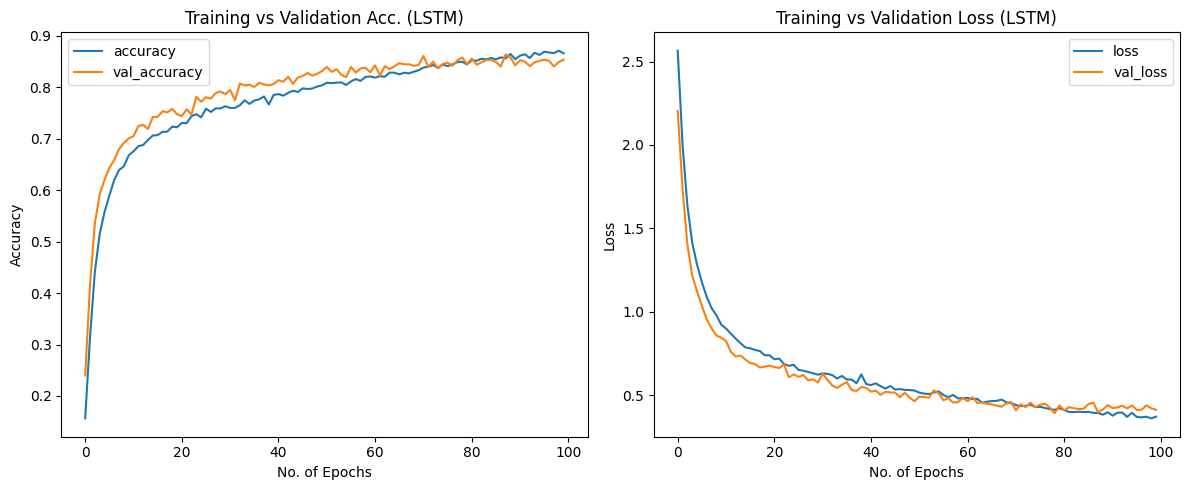

In [45]:
fig,ax = plt.subplots(1,2,figsize=(12,5))
pd.DataFrame(history_lstm.history)[['accuracy','val_accuracy']].plot(ax=ax[0])
ax[0].set_xlabel('No. of Epochs')
ax[0].set_ylabel('Accuracy')
ax[0].set_title('Training vs Validation Acc. (LSTM)')


pd.DataFrame(history_lstm.history)[['loss','val_loss']].plot(ax=ax[1])
ax[1].set_xlabel('No. of Epochs')
ax[1].set_ylabel('Loss')
ax[1].set_title('Training vs Validation Loss (LSTM)')

plt.tight_layout()
plt.savefig('LSTM performance.png',dpi=400)
plt.show()

107/107 ━━━━━━━━━━━━━━━━━━━━ 5s 41ms/step
accuracy score lstm: 0.846335
precision score lstm: 0.846647
recall score lstm: 0.846335
f1 score lstm: 0.843293
107/107 ━━━━━━━━━━━━━━━━━━━━ 4s 39ms/step
 Roc Auc score lstm : 0.993864


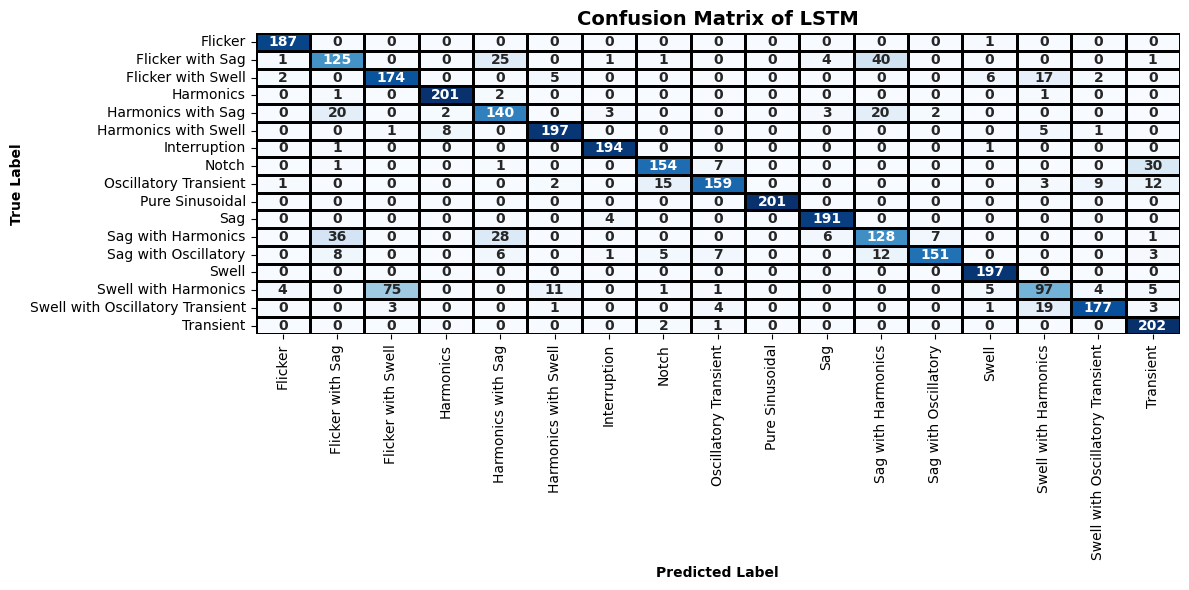

In [46]:

# Check if the target variable is multiclass
is_multiclass = len(np.unique(y)) > 2
y_test_bin = label_binarize(y_test, classes=np.unique(y))

class_labels = ['Flicker', 'Flicker with Sag', 'Flicker with Swell', 'Harmonics',
                'Harmonics with Sag', 'Harmonics with Swell', 'Interruption',
                'Notch', 'Oscillatory Transient', 'Pure Sinusoidal', 'Sag',
                'Sag with Harmonics', 'Sag with Oscillatory', 'Swell',
                'Swell with Harmonics', 'Swell with Oscillatory Transient', 'Transient']

# Convert predicted probabilities to class labels (index of highest probability)
predicted_classes_lstm = np.argmax(model_lstm.predict(X_test), axis=1)

print(f"accuracy score lstm: {accuracy_score(y_test,predicted_classes_lstm):.6f}")
print(f"precision score lstm: {precision_score(y_test,predicted_classes_lstm,average='weighted'):.6f}")
print(f"recall score lstm: {recall_score(y_test,predicted_classes_lstm,average='weighted'):.6f}")
print(f"f1 score lstm: {f1_score(y_test,predicted_classes_lstm,average='weighted'):.6f}")



    # Handle ROC AUC calculation for binary vs. multiclass
if is_multiclass:
        # Predict probabilities for all classes
    y_prob = model_lstm.predict(X_test)

        # Compute micro-average ROC AUC
    fpr, tpr, _ = roc_curve(y_test_bin.ravel(), y_prob.ravel())
    roc_auc = auc(fpr, tpr)
    print(f" Roc Auc score lstm : {roc_auc:.6f}")
else:
        # For binary classification, compute ROC AUC directly
    y_prob = model_lstm.predict(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_auc = auc(fpr, tpr)

cnf = confusion_matrix(y_test,predicted_classes_lstm)
plt.figure(figsize=(12,6))
# Create heatmap with larger, clearer annotations
sns.heatmap(cnf, annot=True, fmt="d", cmap="Blues", xticklabels=class_labels, 
                yticklabels=class_labels, annot_kws={"size": 10, 'weight': 'bold'}, linewidths=1, linecolor='black',cbar=False)

plt.title('Confusion Matrix of LSTM', fontsize=14, fontweight="bold")
plt.xlabel('Predicted Label',fontsize=10,fontweight='bold')
plt.ylabel('True Label',fontsize=10,fontweight='bold')
plt.tight_layout()
plt.show()